# SC4055 Group 8: Quantum kernel SVM vs classical baselines for breast cancer classification

**Question:** does the input representation (PCA-4, MI-4, MI-decorr-4) and the quantum feature map (entangled angle, ZZ) change how a quantum-kernel SVM performs, compared with an RBF SVM and logistic regression on the same data split?

**How to run:** Runtime > Run all. Takes about 30 minutes on Colab, mostly building the quantum kernels. No Google Drive access is needed. Files are saved to the session's temporary disk, so a new session rebuilds everything.

**Sections**
1. Setup and data preprocessing (Laksh)
2. Quantum kernel + SVM (Shanshan)
3. Classical baselines (Narue)
4. Results and analysis (Siri)

**Outputs** (in `DATA_DIR`): `quantum_results.csv`, `classical_results.csv`, `p4_*.csv` tables, and figures in `figures/`.

# Feature selection

In [ ]:
%pip install -q scikit-learn==1.9.1 pennylane==0.45.1
import sys, numpy, pandas, scipy, sklearn, pennylane
print('python', sys.version.split()[0])
for m in (numpy, pandas, scipy, sklearn, pennylane):
    print(f'{m.__name__:10s} {m.__version__}')
assert sklearn.__version__ == '1.9.1', 'wrong scikit-learn version, restart the session and rerun'
assert pennylane.__version__ == '0.45.1', 'wrong PennyLane version, restart the session and rerun'

python 3.13.18
numpy      2.4.6
pandas     2.2.3
scipy      1.16.3
sklearn    1.9.1
pennylane  0.45.1


In [ ]:
import os, sys, glob

USE_DRIVE = False
NOTEBOOK_NAME = 'quantum computing.ipynb'
DATA_DIR_OVERRIDE = None    # put a full path here if the Drive search below fails

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_DRIVE:
    drive.mount('/content/drive')
    if DATA_DIR_OVERRIDE:
        DATA_DIR = DATA_DIR_OVERRIDE
    else:
        hits = glob.glob(f'/content/drive/**/{NOTEBOOK_NAME}', recursive=True)
        assert len(hits) == 1, f'expected one copy of {NOTEBOOK_NAME} on Drive, found {len(hits)}: {hits}'
        DATA_DIR = os.path.join(os.path.dirname(hits[0]), 'data')
elif IN_COLAB:
    DATA_DIR = '/content/sc4055_data'
else:
    DATA_DIR = './sc4055_data'

os.makedirs(DATA_DIR, exist_ok=True)
os.environ['SC4055_DATA_DIR'] = DATA_DIR
if DATA_DIR not in sys.path:
    sys.path.insert(0, DATA_DIR)
print('DATA_DIR =', DATA_DIR)

DATA_DIR = /content/sc4055_data


In [ ]:
%%writefile {DATA_DIR}/preprocessing.py
"""Data loading, train/test split, CV folds and preprocessing.

Every random_state is fixed, so the arrays come out the same on every run. All fitted steps
(power transform, PCA, mutual information selection, angle scaling) are fitted on the
training rows of a fold only and then applied to that fold's validation or test rows.
"""
from __future__ import annotations

import hashlib
import json
import os

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, PowerTransformer

# Settings shared by every section of the notebook
SEED = 0                      # used by the split, the CV folds, PCA and mutual_info_classif
TEST_SIZE = 0.2               # gives 455 train rows and 114 test rows
N_SPLITS, N_REPEATS = 5, 3    # 5-fold CV repeated 3 times = 15 folds
N_FOLDS = N_SPLITS * N_REPEATS
N_FEAT = 4                    # one feature per qubit
ANGLE_RANGE = (0.0, np.pi)    # range of the rotation angles fed to the feature maps
CORR_THRESHOLD = 0.9          # largest |r| allowed between two features in "mi_decorr"
REPS = ("pca", "mi", "mi_decorr")
ARRAYS_FILE = "arrays.npz"
MANIFEST_FILE = "manifest.json"
DATA_DIR = os.environ.get("SC4055_DATA_DIR", ".")


def load_data():
    """Return X as a (569, 30) DataFrame and y as a (569,) int array with 1 = malignant.

    sklearn codes malignant as 0. We flip it here so that the default pos_label=1 in
    recall, F1 and ROC-AUC refers to the malignant class in every later section.
    """
    d = load_breast_cancer(as_frame=True)
    X = d.data.copy()
    y = (d.target.values == 0).astype(int)
    assert y.sum() == 212 and len(y) == 569      # 212 malignant, 357 benign
    return X, y


def make_splits():
    """Stratified 80/20 train/test split, then 15 stratified CV folds inside the train set.

    All indices are row numbers into the full 569-row X from load_data().
      train_idx (455,), test_idx (114,)
      fit_idx (15, 364): rows used to fit models and transforms in fold f
      val_idx (15, 91):  rows used to score fold f
    Folds 0-4 are the first full 5-fold pass, 5-9 the second and 10-14 the third.
    """
    X, y = load_data()
    all_idx = np.arange(len(y))
    train_idx, test_idx = train_test_split(
        all_idx, test_size=TEST_SIZE, stratify=y, random_state=SEED)
    train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)
    cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    fit_idx, val_idx = [], []
    for a, b in cv.split(train_idx, y[train_idx]):
        fit_idx.append(train_idx[a]); val_idx.append(train_idx[b])
    return dict(train_idx=train_idx, test_idx=test_idx,
                fit_idx=np.array(fit_idx), val_idx=np.array(val_idx))


class MISelector(BaseEstimator, TransformerMixin):
    """Keeps the n_feat features with the highest mutual information with y.

    With decorr_threshold=None this is plain top-n MI ("mi"). With a threshold, we walk down
    the MI ranking and skip any feature whose |Pearson r| with an already kept feature is
    above the threshold ("mi_decorr"). We added the second version because the top MI
    features (worst radius, perimeter and area) are almost copies of each other.
    """

    def __init__(self, n_feat=N_FEAT, decorr_threshold=None, random_state=SEED):
        self.n_feat = n_feat
        self.decorr_threshold = decorr_threshold
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        mi = mutual_info_classif(X, y, random_state=self.random_state)
        order = np.argsort(-mi, kind="stable")     # highest MI first, ties keep column order
        if self.decorr_threshold is None:
            keep = list(order[: self.n_feat])
        else:
            C = np.abs(np.corrcoef(X, rowvar=False))
            keep = []
            for j in order:
                if all(C[j, k] <= self.decorr_threshold for k in keep):
                    keep.append(j)
                if len(keep) == self.n_feat:
                    break
        self.mi_ = mi
        self.support_idx_ = np.array(keep)
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.support_idx_]


def build_pipeline(rep, n_feat=N_FEAT):
    """Return an unfitted Pipeline for one representation ("pca", "mi" or "mi_decorr").

    Yeo-Johnson transform and standardise all 30 features, reduce to n_feat, then MinMax
    scale to [0, pi]. clip=True means validation or test values that fall outside the
    training range are clipped to 0 or pi.
    """
    if rep == "pca":
        reducer = PCA(n_components=n_feat, random_state=SEED)
    elif rep == "mi":
        reducer = MISelector(n_feat=n_feat)
    elif rep == "mi_decorr":
        reducer = MISelector(n_feat=n_feat, decorr_threshold=CORR_THRESHOLD)
    else:
        raise ValueError(f"rep must be one of {REPS}, got {rep!r}")
    return Pipeline([
        ("power", PowerTransformer(method="yeo-johnson", standardize=True)),
        ("reduce", reducer),
        ("angle", MinMaxScaler(feature_range=ANGLE_RANGE, clip=True)),
    ])


def transform_fold(X_fit, y_fit, X_eval, rep, n_feat=N_FEAT):
    """Fit the pipeline on the fit rows only, then transform both the fit and eval rows.

    Returns Z_fit, Z_eval and an info dict with:
      features      names of the kept features, or PC1..PCn for PCA
      pca_cumvar    cumulative explained variance of the kept components (PCA only)
      n_clipped     how many eval values fell outside [0, pi] and were clipped
      rows_clipped  how many eval rows had at least one clipped value
    """
    pipe = build_pipeline(rep, n_feat).fit(X_fit, y_fit)
    Z_fit, Z_eval = pipe.transform(X_fit), pipe.transform(X_eval)
    mm = pipe.named_steps["angle"]
    raw = pipe[:-1].transform(X_eval) * mm.scale_ + mm.min_       # eval values before clipping
    out = (raw < ANGLE_RANGE[0]) | (raw > ANGLE_RANGE[1])
    names = list(X_fit.columns) if hasattr(X_fit, "columns") else None
    info = dict(n_clipped=int(out.sum()), rows_clipped=int(out.any(axis=1).sum()))
    red = pipe.named_steps["reduce"]
    if rep == "pca":
        info["features"] = [f"PC{i + 1}" for i in range(n_feat)]
        info["pca_cumvar"] = [round(float(v), 4) for v in red.explained_variance_ratio_.cumsum()]
    else:
        info["features"] = [names[j] for j in red.support_idx_] if names else red.support_idx_.tolist()
    return Z_fit, Z_eval, info


def _rounded_sha(a):
    # Round first so floating point noise in the last digits does not change the hash
    return hashlib.sha256(np.round(np.asarray(a, dtype=float), 6).tobytes()).hexdigest()[:16]


def build_all(out_dir=None, n_feat=N_FEAT, reps=REPS, verbose=True):
    """Build the arrays for all 15 folds and the final split, for every representation.

    Saves them to ARRAYS_FILE and writes MANIFEST_FILE with the library versions, settings,
    selected features per fold, clipping counts and checksums.
    Keys in the .npz: y, train_idx, test_idx, fit_idx, val_idx, and for each rep R:
      R__fit (15, 364, n_feat), R__val (15, 91, n_feat), R__train (455, n_feat), R__test (114, n_feat)
    """
    import scipy
    import sklearn
    out_dir = out_dir or DATA_DIR
    os.makedirs(out_dir, exist_ok=True)
    X, y = load_data()
    s = make_splits()
    arrays = dict(y=y, **s)
    manifest = dict(versions=dict(sklearn=sklearn.__version__, numpy=np.__version__,
                                  pandas=pd.__version__, scipy=scipy.__version__),
                    config=dict(SEED=SEED, TEST_SIZE=TEST_SIZE, N_SPLITS=N_SPLITS,
                                N_REPEATS=N_REPEATS, N_FEAT=n_feat, ANGLE_RANGE=list(ANGLE_RANGE),
                                CORR_THRESHOLD=CORR_THRESHOLD, label="1 = malignant"),
                    folds={}, final={}, checksums={})
    for rep in reps:
        F, V, fold_info = [], [], []
        for f in range(N_FOLDS):
            a, b = s["fit_idx"][f], s["val_idx"][f]
            Zf, Zv, info = transform_fold(X.iloc[a], y[a], X.iloc[b], rep, n_feat)
            F.append(Zf); V.append(Zv); fold_info.append(info)
        Ztr, Zte, finfo = transform_fold(X.iloc[s["train_idx"]], y[s["train_idx"]],
                                         X.iloc[s["test_idx"]], rep, n_feat)
        arrays[f"{rep}__fit"], arrays[f"{rep}__val"] = np.array(F), np.array(V)
        arrays[f"{rep}__train"], arrays[f"{rep}__test"] = Ztr, Zte
        manifest["folds"][rep] = fold_info
        manifest["final"][rep] = finfo
        for k in ("fit", "val", "train", "test"):
            manifest["checksums"][f"{rep}__{k}"] = _rounded_sha(arrays[f"{rep}__{k}"])
    path = os.path.join(out_dir, ARRAYS_FILE)
    np.savez_compressed(path, **arrays)
    with open(path, "rb") as fh:
        manifest["npz_sha256"] = hashlib.sha256(fh.read()).hexdigest()
    with open(os.path.join(out_dir, MANIFEST_FILE), "w") as fh:
        json.dump(manifest, fh, indent=1)
    if verbose:
        print(f"saved {path}  sha256={manifest['npz_sha256'][:16]}")
    return arrays, manifest


# Comparing a new build with our reference run.
# Exact hashes don't match across machines, because PowerTransformer fits its lambda with a
# scipy optimiser and that can move values by about 1e-7. So instead we check that the same
# features get picked in every fold and that a few summary numbers agree to within ATOL.
ATOL = 1e-5
_SAMPLE_POS = (0, 7, 101, 333, -1)


def summarize(arrays):
    """Mean, std, min, max and five fixed entries of each feature array."""
    out = {}
    for k, v in arrays.items():
        if "__" in k:
            f = np.asarray(v, dtype=float).ravel()
            out[k] = [round(float(x), 8) for x in
                      (f.mean(), f.std(), f.min(), f.max(), *[f[i] for i in _SAMPLE_POS])]
    return out


def check_reference(arrays, manifest, ref_summary, ref_features, atol=ATOL):
    """Return a list of differences from the reference run. An empty list means it matches."""
    problems = []
    for rep, feats in ref_features.items():
        got = [info["features"] for info in manifest["folds"][rep]] + [manifest["final"][rep]["features"]]
        if got != feats:
            problems.append(f"{rep}: selected features differ from the reference")
    mine = summarize(arrays)
    for k, ref in ref_summary.items():
        d = float(np.max(np.abs(np.array(mine[k]) - np.array(ref))))
        if d > atol:
            problems.append(f"{k}: differs from reference by {d:.1e} (> {atol:.0e})")
    return problems


# Reading the saved arrays. Other sections should only need get_fold and get_final.
_CACHE = {}


def _load(path=None):
    path = path or os.path.join(DATA_DIR, ARRAYS_FILE)
    if path not in _CACHE:
        if not os.path.exists(path):
            raise FileNotFoundError(f"{path} not found. Run build_all() or set SC4055_DATA_DIR.")
        _CACHE[path] = dict(np.load(path))
    return _CACHE[path]


def get_fold(rep, f, path=None):
    """Return Z_fit (364, 4), y_fit, Z_val (91, 4), y_val for CV fold f (0 to 14)."""
    A = _load(path)
    return (A[f"{rep}__fit"][f], A["y"][A["fit_idx"][f]],
            A[f"{rep}__val"][f], A["y"][A["val_idx"][f]])


def get_final(rep, path=None):
    """Return Z_train (455, 4), y_train, Z_test (114, 4), y_test.

    Only score on the test arrays after hyperparameters have been chosen on the CV folds.
    """
    A = _load(path)
    return (A[f"{rep}__train"], A["y"][A["train_idx"]],
            A[f"{rep}__test"], A["y"][A["test_idx"]])


def selection_frequency(manifest):
    """Count how often each original feature was selected across the 15 folds, per rep."""
    rows = {}
    for rep in ("mi", "mi_decorr"):
        if rep in manifest["folds"]:
            counts = pd.Series([n for info in manifest["folds"][rep] for n in info["features"]]).value_counts()
            rows[rep] = counts
    return pd.DataFrame(rows).fillna(0).astype(int).sort_values(list(rows), ascending=False)


def self_test(arrays, manifest):
    """Check shapes, value ranges, label counts and that the splits don't overlap.

    Also checks that no test or validation rows leak into the fitted transforms.
    Raises AssertionError if anything fails.
    """
    X, y = load_data()
    s = make_splits()
    assert len(s["train_idx"]) == 455 and len(s["test_idx"]) == 114
    assert not set(s["train_idx"]) & set(s["test_idx"])
    assert y[s["test_idx"]].sum() == 42 and y[s["train_idx"]].sum() == 170
    for f in range(N_FOLDS):
        a, b = s["fit_idx"][f], s["val_idx"][f]
        assert not set(a) & set(b) and set(a) | set(b) == set(s["train_idx"])
        assert not set(b) & set(s["test_idx"])
    for r in range(N_REPEATS):        # each repeat's validation folds should cover train exactly once
        vals = np.concatenate(s["val_idx"][r * N_SPLITS:(r + 1) * N_SPLITS])
        assert sorted(vals) == sorted(s["train_idx"])
    for k, v in arrays.items():
        if "__" in k:
            assert v.min() >= ANGLE_RANGE[0] and v.max() <= ANGLE_RANGE[1], k
            assert np.isfinite(v).all(), k
    # Leakage test 1: scramble the test rows. If nothing leaks, the train arrays stay identical.
    Xp = X.copy()
    rng = np.random.default_rng(1)
    Xp.iloc[s["test_idx"]] = rng.permutation(Xp.iloc[s["test_idx"]].values) * 3.0
    for rep in REPS:
        Ztr, _, _ = transform_fold(Xp.iloc[s["train_idx"]], y[s["train_idx"]],
                                   Xp.iloc[s["test_idx"]], rep)
        assert np.array_equal(Ztr, arrays[f"{rep}__train"]), f"test rows leak into {rep}"
    # Leakage test 2: same idea with the validation rows of fold 0.
    a, b = s["fit_idx"][0], s["val_idx"][0]
    Xq = X.copy(); Xq.iloc[b] = Xq.iloc[b].values[::-1] * 2.0
    for rep in REPS:
        Zf, _, _ = transform_fold(Xq.iloc[a], y[a], Xq.iloc[b], rep)
        assert np.array_equal(Zf, arrays[f"{rep}__fit"][0]), f"val rows leak into {rep}"
    print("self_test passed: shapes, ranges, disjoint splits, labels, no test or fold leakage")


Writing /content/sc4055_data/preprocessing.py


In [ ]:
# Summary numbers from our reference run on 2 Nov 2026 (sklearn 1.9.1).
# These are fixed values typed here, so they do not change between sessions.
# The next cells build the arrays again and compare them against these numbers.
REF_SUMMARY = {'pca__fit': [1.45819412,
              0.59185532,
              0.0,
              3.14159265,
              2.78508289,
              1.32089704,
              1.45874049,
              1.02946458,
              2.33693157],
 'pca__val': [1.45760893,
              0.59050339,
              0.0,
              3.14159265,
              2.35397651,
              2.66970381,
              0.60175862,
              1.53817798,
              2.21590926],
 'pca__train': [1.45919159,
                0.58336916,
                0.0,
                3.14159265,
                2.78469249,
                1.15891057,
                1.35306518,
                1.00367036,
                2.3836697],
 'pca__test': [1.4601673,
               0.56142139,
               0.02826458,
               3.11402853,
               2.21603745,
               1.62511284,
               1.49075192,
               1.23256595,
               2.46296545],
 'mi__fit': [1.64723401,
             0.66526018,
             0.0,
             3.14159265,
             2.75767299,
             2.3900128,
             1.76915189,
             2.19652408,
             0.54136033],
 'mi__val': [1.64936228,
             0.66187008,
             0.0,
             3.14159265,
             1.68084586,
             2.25854891,
             2.80913814,
             1.71032695,
             2.55568886],
 'mi__train': [1.70163366,
               0.6161948,
               0.0,
               3.14159265,
               2.76899575,
               2.65730395,
               2.28790037,
               1.46021077,
               0.54910422],
 'mi__test': [1.73457093,
              0.60386886,
              0.0,
              3.11562389,
              2.49286132,
              2.51968129,
              1.53724311,
              1.15844785,
              1.18437927],
 'mi_decorr__fit': [1.58964578,
                    0.67987096,
                    0.0,
                    3.14159265,
                    2.75767299,
                    1.3581665,
                    2.70922573,
                    2.07054061,
                    0.0],
 'mi_decorr__val': [1.59098218,
                    0.68066222,
                    0.0,
                    3.14159265,
                    1.68084586,
                    2.8867105,
                    2.77367434,
                    1.83304701,
                    2.86589086],
 'mi_decorr__train': [1.61941668,
                      0.64838576,
                      0.0,
                      3.14159265,
                      2.76899575,
                      1.32856385,
                      2.3845246,
                      1.30229119,
                      0.38871009],
 'mi_decorr__test': [1.65743563,
                     0.63081875,
                     0.0,
                     3.11562389,
                     2.49286132,
                     1.70803612,
                     1.14460399,
                     0.68163061,
                     0.29490614]}

REF_FEATURES = {'mi': [['worst perimeter', 'worst radius', 'worst area', 'worst concave points'],
        ['worst perimeter', 'worst area', 'worst radius', 'worst concave points'],
        ['worst concave points', 'worst perimeter', 'mean concave points', 'worst area'],
        ['worst concave points', 'mean concave points', 'worst perimeter', 'worst area'],
        ['mean concave points', 'worst perimeter', 'worst area', 'worst radius'],
        ['worst perimeter', 'worst radius', 'worst area', 'mean concave points'],
        ['worst perimeter', 'worst area', 'worst concave points', 'worst radius'],
        ['worst perimeter', 'worst area', 'mean concave points', 'worst radius'],
        ['worst concave points', 'mean concave points', 'worst perimeter', 'worst radius'],
        ['worst perimeter', 'worst concave points', 'worst area', 'mean concave points'],
        ['worst perimeter', 'worst concave points', 'worst area', 'worst radius'],
        ['worst perimeter', 'mean concave points', 'worst area', 'worst concave points'],
        ['worst perimeter', 'worst area', 'worst concave points', 'mean concave points'],
        ['worst perimeter', 'worst concave points', 'worst radius', 'worst area'],
        ['mean concave points', 'worst radius', 'worst perimeter', 'worst area'],
        ['worst perimeter', 'worst area', 'worst concave points', 'worst radius']],
 'mi_decorr': [['worst perimeter', 'worst concave points', 'area error', 'worst compactness'],
               ['worst perimeter', 'worst concave points', 'area error', 'worst concavity'],
               ['worst concave points', 'worst perimeter', 'area error', 'worst compactness'],
               ['worst concave points', 'worst perimeter', 'worst concavity', 'area error'],
               ['mean concave points', 'worst perimeter', 'area error', 'worst concavity'],
               ['worst perimeter', 'mean concave points', 'area error', 'worst concavity'],
               ['worst perimeter', 'worst concave points', 'area error', 'mean compactness'],
               ['worst perimeter', 'mean concave points', 'area error', 'worst concavity'],
               ['worst concave points', 'worst perimeter', 'area error', 'mean compactness'],
               ['worst perimeter', 'worst concave points', 'area error', 'worst compactness'],
               ['worst perimeter', 'worst concave points', 'area error', 'worst compactness'],
               ['worst perimeter', 'mean concave points', 'area error', 'worst concavity'],
               ['worst perimeter', 'worst concave points', 'area error', 'mean compactness'],
               ['worst perimeter', 'worst concave points', 'area error', 'worst compactness'],
               ['mean concave points', 'worst radius', 'area error', 'worst concavity'],
               ['worst perimeter', 'worst concave points', 'area error', 'worst compactness']]}


In [ ]:
import importlib, json
import preprocessing as prep
importlib.reload(prep)              # load the version of preprocessing.py written above
prep.DATA_DIR = DATA_DIR

# Building the arrays for a fresh session
# Set REBUILD = True to force a rebuild after editing preprocessing.py.
REBUILD = False
arrays_path = os.path.join(DATA_DIR, prep.ARRAYS_FILE)
if REBUILD or not os.path.exists(arrays_path):
    arrays, manifest = prep.build_all(DATA_DIR)
    prep.self_test(arrays, manifest)
with open(os.path.join(DATA_DIR, prep.MANIFEST_FILE)) as fh:
    manifest = json.load(fh)
print('npz sha256:', manifest['npz_sha256'])
print('built with:', manifest['versions'])

saved /content/sc4055_data/arrays.npz  sha256=096472049bdb1b36
self_test passed: shapes, ranges, disjoint splits, labels, no test or fold leakage
npz sha256: 096472049bdb1b3631a63a4d629c200ab0aa5815c95dc5c8dd8c50f5c6556ff2
built with: {'sklearn': '1.9.1', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3'}


In [ ]:
# Compare this build with the reference run: the same features must be picked in every fold,
# and every array summary must agree to within 1e-5. Differences of around 1e-7 between
# machines are normal (they come from scipy's optimiser inside PowerTransformer).
arrays = prep._load(arrays_path)
problems = prep.check_reference(arrays, manifest, REF_SUMMARY, REF_FEATURES)
print('all arrays match the reference build' if not problems else 'MISMATCH:\n' + '\n'.join(problems))

# Shape check on fold 0 and the final split
Z_fit, y_fit, Z_val, y_val = prep.get_fold('pca', 0)
Z_tr, y_tr, Z_te, y_te = prep.get_final('pca')
print('fold 0 :', Z_fit.shape, y_fit.shape, Z_val.shape, y_val.shape)
print('final  :', Z_tr.shape, y_tr.shape, Z_te.shape, y_te.shape)
print('malignant in train/test:', y_tr.sum(), y_te.sum())

all arrays match the reference build
fold 0 : (364, 4) (364,) (91, 4) (91,)
final  : (455, 4) (455,) (114, 4) (114,)
malignant in train/test: 170 42


### Selected features and clipping

In [ ]:
# How often each original feature was picked across the 15 folds, plus how many
# validation rows and test values had to be clipped into [0, pi]
print(prep.selection_frequency(manifest).to_string())
for rep in prep.REPS:
    fold_info = manifest['folds'][rep]
    print(f"{rep:10s} final features: {manifest['final'][rep]['features']}")
    print(f"{'':10s} val rows clipped per fold: {[i['rows_clipped'] for i in fold_info]}; "
          f"test values clipped: {manifest['final'][rep]['n_clipped']}")
print('PCA-4 cumulative variance (final fit):', manifest['final']['pca']['pca_cumvar'][-1])

                      mi  mi_decorr
worst perimeter       15         14
worst area            14          0
worst concave points  11         10
mean concave points   10          5
worst radius          10          1
area error             0         15
worst concavity        0          7
worst compactness      0          5
mean compactness       0          3
pca        final features: ['PC1', 'PC2', 'PC3', 'PC4']
           val rows clipped per fold: [1, 0, 4, 6, 1, 0, 1, 3, 1, 3, 3, 1, 4, 3, 0]; test values clipped: 0
mi         final features: ['worst perimeter', 'worst area', 'worst concave points', 'worst radius']
           val rows clipped per fold: [0, 0, 0, 6, 1, 1, 0, 0, 2, 1, 1, 2, 0, 3, 0]; test values clipped: 0
mi_decorr  final features: ['worst perimeter', 'worst concave points', 'area error', 'worst compactness']
           val rows clipped per fold: [2, 0, 1, 6, 2, 1, 0, 0, 2, 2, 3, 2, 0, 4, 0]; test values clipped: 0
PCA-4 cumulative variance (final fit): 0.8135


### Data summary

In [ ]:
# Facts about the dataset that shaped the preprocessing choices.
# Counts use all 569 rows. Anything that informed a modelling choice (skew, correlation)
# is computed on the 455 training rows only, so the test set plays no part in it.
import numpy as np
import pandas as pd

X, y = prep.load_data()
s = prep.make_splits()
X_train, y_train = X.iloc[s['train_idx']], y[s['train_idx']]

print(f'samples: {X.shape[0]}, features: {X.shape[1]}')
print(f'malignant: {y.sum()} ({y.mean():.1%}), benign: {(y == 0).sum()} ({1 - y.mean():.1%})')
print(f"train: {len(s['train_idx'])} rows, {y_train.sum()} malignant | "
      f"test: {len(s['test_idx'])} rows, {y[s['test_idx']].sum()} malignant")
print('missing values:', int(X.isna().sum().sum()))

# Feature scales: the column maxima span five orders of magnitude, so scaling is needed
col_max = X.max()
print(f'smallest column max: {col_max.min():.4f} ({col_max.idxmin()})')
print(f'largest column max:  {col_max.max():.0f} ({col_max.idxmax()})')

# Skew on the training rows, before and after the Yeo-Johnson step the pipeline uses
power = prep.build_pipeline('pca').named_steps['power'].fit(X_train)
skew_raw = X_train.skew()
skew_yj = pd.DataFrame(power.transform(X_train), columns=X.columns).skew()
top = skew_raw.sort_values(ascending=False).head(5).index
print('\nmost skewed features (training rows):')
print(pd.DataFrame({'raw skew': skew_raw[top], 'after Yeo-Johnson': skew_yj[top]}).round(2).to_string())
print(f'features with |skew| > 1: raw {int((skew_raw.abs() > 1).sum())}, '
      f'after Yeo-Johnson {int((skew_yj.abs() > 1).sum())}')

# The three "worst" size features are close to copies of each other
size = ['worst radius', 'worst perimeter', 'worst area']
print('\ncorrelation of the size features (training rows):')
print(X_train[size].corr().round(3).to_string())

# Average |r| between the 4 features each representation hands to the models (final fit)
def mean_abs_r(Z):
    C = np.abs(np.corrcoef(Z, rowvar=False))
    return C[np.triu_indices_from(C, k=1)].mean()

print('\nmean |r| between the 4 model inputs (training rows):')
for rep in prep.REPS:
    Z_tr, _, _, _ = prep.get_final(rep)
    print(f'  {rep:10s} {mean_abs_r(Z_tr):.2f}')


samples: 569, features: 30
malignant: 212 (37.3%), benign: 357 (62.7%)
train: 455 rows, 170 malignant | test: 114 rows, 42 malignant
missing values: 0
smallest column max: 0.0298 (fractal dimension error)
largest column max:  4254 (worst area)

most skewed features (training rows):
                         raw skew  after Yeo-Johnson
area error                   5.73               0.07
concavity error              5.29               0.16
fractal dimension error      4.08               0.26
perimeter error              3.66               0.08
radius error                 3.31               0.20
features with |skew| > 1: raw 24, after Yeo-Johnson 0

correlation of the size features (training rows):
                 worst radius  worst perimeter  worst area
worst radius            1.000            0.994       0.984
worst perimeter         0.994            1.000       0.978
worst area              0.984            0.978       1.000

mean |r| between the 4 model inputs (training rows):
  pc

In [ ]:
# Why Yeo-Johnson: share of fit rows below pi/4 for the most bunched feature,
# averaged over the 15 folds, with StandardScaler vs Yeo-Johnson as the first step
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
for rep in prep.REPS:
    out = {}
    for name in ("StandardScaler", "Yeo-Johnson"):
        fr = []
        for f in range(prep.N_FOLDS):
            pipe = prep.build_pipeline(rep)
            if name == "StandardScaler":
                pipe = Pipeline([("power", StandardScaler())] + pipe.steps[1:])
            a = s["fit_idx"][f]
            Z = pipe.fit(X.iloc[a], y[a]).transform(X.iloc[a])
            fr.append((Z < np.pi / 4).mean(axis=0).max())
        out[name] = f"{np.mean(fr):.0%}"
    print(rep, out)

pca {'StandardScaler': '60%', 'Yeo-Johnson': '18%'}
mi {'StandardScaler': '77%', 'Yeo-Johnson': '18%'}
mi_decorr {'StandardScaler': '86%', 'Yeo-Johnson': '21%'}


### PCA explained variance

cumulative variance, components 1 to 8: [0.4652, 0.6546, 0.7514, 0.8135, 0.8664, 0.9041, 0.9274, 0.9423]
k = 4: 81.35% of the variance
k = 4 across the 15 CV folds: 80.6% to 82.0% (mean 81.4%)


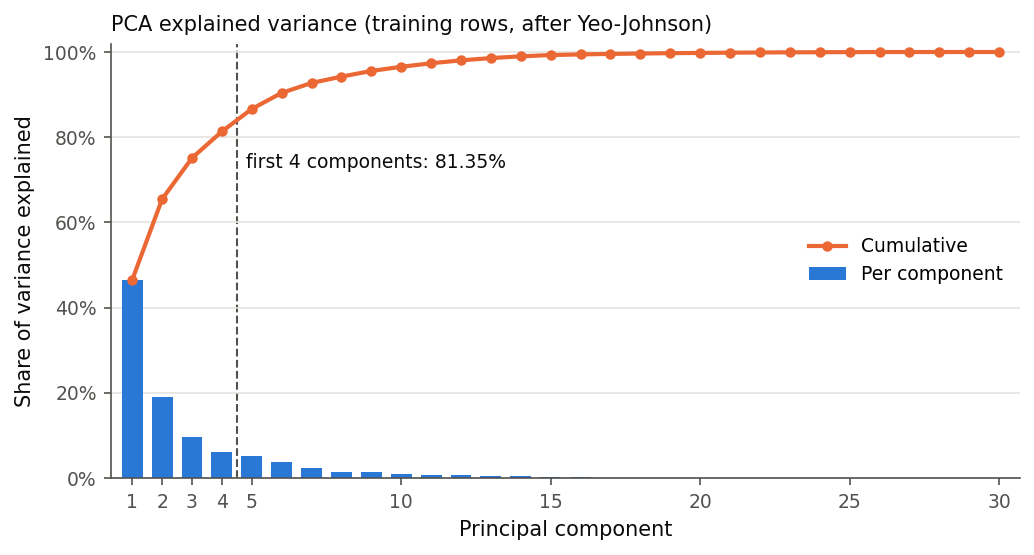

saved /content/sc4055_data/pca_explained_variance.png


In [ ]:
# Explained variance of every principal component, fit on the 455 training rows after the
# same Yeo-Johnson + standardise step the pipeline uses. The dashed line marks k = 4, the
# number of components we keep (one per qubit).
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca_all = PCA(random_state=prep.SEED).fit(power.transform(X_train))
ratio = pca_all.explained_variance_ratio_
cum = ratio.cumsum()
k = prep.N_FEAT
comp = np.arange(1, len(ratio) + 1)

print('cumulative variance, components 1 to 8:', np.round(cum[:8], 4).tolist())
print(f'k = {k}: {cum[k - 1]:.2%} of the variance')
fold_cum = [info['pca_cumvar'][-1] for info in manifest['folds']['pca']]
print(f'k = {k} across the 15 CV folds: {min(fold_cum):.1%} to {max(fold_cum):.1%} '
      f'(mean {np.mean(fold_cum):.1%})')

BAR, LINE = '#2a78d6', '#eb6834'      # colour-blind safe pair
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'

fig, ax = plt.subplots(figsize=(7, 3.8), dpi=150)
ax.bar(comp, ratio, width=0.7, color=BAR, label='Per component', zorder=2)
ax.plot(comp, cum, color=LINE, lw=2, marker='o', ms=4, label='Cumulative', zorder=3)
ax.axvline(k + 0.5, color=MUTED, ls='--', lw=1, zorder=1)
ax.text(k + 0.8, cum[k - 1] - 0.05, f'first {k} components: {cum[k - 1]:.2%}',
        color=INK, fontsize=9, ha='left', va='top')
ax.set_xlabel('Principal component', color=INK)
ax.set_ylabel('Share of variance explained', color=INK)
ax.set_xlim(0.3, len(comp) + 0.7)
ax.set_ylim(0, 1.02)
ax.set_xticks([1, 2, 3, 4] + list(range(5, len(comp) + 1, 5)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.grid(axis='y', color=GRID, lw=0.8, zorder=0)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for side in ('left', 'bottom'):
    ax.spines[side].set_color(MUTED)
ax.tick_params(colors=MUTED, labelsize=9)
ax.legend(frameon=False, loc='center right', fontsize=9)
ax.set_title('PCA explained variance (training rows, after Yeo-Johnson)', color=INK, fontsize=10, loc='left')
fig.tight_layout()
fig_path = os.path.join(DATA_DIR, 'pca_explained_variance.png')
fig.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('saved', fig_path)

#Quantum kernel + SVM

This section is on quantum feature maps & fidelity kernels (PennyLane, default.qubit). The classical model we will be using for classification later is SVM.

Experiments for this section are:

*   E1: PCA 4 comps + entangled angle map
*   E2: PCA 4 comps + ZZ map
*   E3: 4 selected feats (MI)  + entangled angle map
*   E4: 4 selected feats (MI)  + ZZ map
*   E5: 4 decorrelated feats   + entangled angle map
*   E6: 4 decorrelated feats   + ZZ map
    
Kernels are built for every CV fold and the final train/test split,
and cached in DATA_DIR/kernel_cache.

In [ ]:
import os
import sys
import time
import hashlib

import numpy as np
import pennylane as qml
from sklearn.svm import SVC

if DATA_DIR not in sys.path:
    sys.path.insert(0, DATA_DIR)
import importlib
importlib.invalidate_caches()
import preprocessing as prep
importlib.reload(prep)
prep.DATA_DIR = DATA_DIR

In [ ]:
# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
N_QUBITS = 4
ZZ_REPS = 2
ANGLE_REPS = 2          # layers of the entangled angle map
SEED = 42
CACHE_DIR = os.path.join(DATA_DIR, "kernel_cache")

# Bandwidth (feature-scaling factor): the features are multiplied by this number
# before they enter the circuit. It is the quantum analogue of the RBF gamma:
# a small factor gives a smoother kernel, 1.0 is the unscaled map used before.
# It is tuned by CV together with C, like gamma for the classical RBF SVM.
BANDWIDTHS = [0.05, 0.1, 0.25, 0.5, 1.0]

EXPERIMENTS = {
    "E1": {"representation": "pca4",      "feature_map": "angle_ent"},
    "E2": {"representation": "pca4",      "feature_map": "zz"},
    "E3": {"representation": "selected4", "feature_map": "angle_ent"},
    "E4": {"representation": "selected4", "feature_map": "zz"},
    "E5": {"representation": "decorr4",   "feature_map": "angle_ent"},
    "E6": {"representation": "decorr4",   "feature_map": "zz"},
}


REP_NAME = {"pca4": "pca", "selected4": "mi", "decorr4": "mi_decorr"}

dev = qml.device("default.qubit", wires=N_QUBITS)


# ----------------------------------------------------------------------------
# Feature maps
# ----------------------------------------------------------------------------
def angle_ent_map(x, wires, reps=ANGLE_REPS):
    """
    Entangled angle encoding.

    Each repetition: RY(x_i) then RZ(x_i) on every qubit (angle encoding with
    two non-commuting rotation axes), followed by a ring of CNOTs
    (0->1, 1->2, ..., n-1->0) that entangles the qubits.
    """
    n = len(wires)
    for _ in range(reps):
        for i in range(n):
            qml.RY(x[i], wires=wires[i])
            qml.RZ(x[i], wires=wires[i])
        for i in range(n):
            qml.CNOT(wires=[wires[i], wires[(i + 1) % n]])


def zz_map(x, wires, reps=ZZ_REPS):
    """
    Each repetition: H on all qubits -> RZ(2 x_i) on each qubit
                     -> for every pair (i, j): CNOT, RZ(2 (pi-x_i)(pi-x_j)), CNOT
    """
    n = len(wires)
    for _ in range(reps):
        for i in range(n):
            qml.Hadamard(wires=wires[i])
            qml.RZ(2.0 * x[i], wires=wires[i])
        for i in range(n):
            for j in range(i + 1, n):
                qml.CNOT(wires=[wires[i], wires[j]])
                qml.RZ(2.0 * (np.pi - x[i]) * (np.pi - x[j]), wires=wires[j])
                qml.CNOT(wires=[wires[i], wires[j]])


FEATURE_MAPS = {"angle_ent": angle_ent_map, "zz": zz_map}


def draw_circuit(feature_map, x=None):
    """Text diagram of the circuit."""
    x = np.array([0.3, 0.6, 0.9, 1.2]) if x is None else x
    fmap = FEATURE_MAPS[feature_map]

    @qml.qnode(dev)
    def circuit(x):
        fmap(x, wires=range(N_QUBITS))
        return qml.state()

    return qml.draw(circuit)(x)


# ----------------------------------------------------------------------------
# Fidelity kernel   K(x, z) = |<phi(x)|phi(z)>|^2
# ----------------------------------------------------------------------------
def compute_statevectors(X, feature_map):
    """Simulate the feature-map circuit once per sample -> (n, 2**n_qubits)."""
    fmap = FEATURE_MAPS[feature_map]

    @qml.qnode(dev)
    def circuit(x):
        fmap(x, wires=range(N_QUBITS))
        return qml.state()

    return np.array([circuit(x) for x in X])


def kernel_from_states(states_a, states_b):
    """Exact fidelity kernel from stored statevectors."""
    return np.abs(states_a @ states_b.conj().T) ** 2


def kernel_pair_circuit(x, z, feature_map):
    """Slow reference: U(x)^dagger U(z) circuit, probability of |0...0>."""
    fmap = FEATURE_MAPS[feature_map]

    @qml.qnode(dev)
    def circuit(x, z):
        fmap(z, wires=range(N_QUBITS))
        qml.adjoint(fmap)(x, wires=range(N_QUBITS))
        return qml.probs(wires=range(N_QUBITS))

    return circuit(x, z)[0]


def compute_kernels(X_train, X_test, feature_map, scale=1.0):
    """Returns K_train (n_train x n_train), K_test (n_test x n_train), timing dict.
    The features are multiplied by `scale` (the bandwidth) before encoding."""
    t0 = time.perf_counter()
    S_train = compute_statevectors(scale * np.asarray(X_train), feature_map)
    S_test = compute_statevectors(scale * np.asarray(X_test), feature_map)
    t1 = time.perf_counter()
    K_train = kernel_from_states(S_train, S_train)
    K_test = kernel_from_states(S_test, S_train)
    t2 = time.perf_counter()
    timing = {"statevector_s": t1 - t0, "kernel_matrix_s": t2 - t1, "total_s": t2 - t0}
    return K_train, K_test, timing


# ----------------------------------------------------------------------------
# Sanity checks
# ----------------------------------------------------------------------------
def check_kernel(K_train, K_test, X_train, feature_map, n_pairs=20, seed=SEED):
    """Symmetry, diagonal, value range, PSD, and agreement with the pair circuit.
    X_train must be the SCALED features that the kernel was built from."""
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X_train), size=2 * n_pairs, replace=False).reshape(n_pairs, 2)
    ref = np.array([kernel_pair_circuit(X_train[i], X_train[j], feature_map) for i, j in idx])
    fast = np.array([K_train[i, j] for i, j in idx])

    report = {
        "symmetric": bool(np.allclose(K_train, K_train.T, atol=1e-10)),
        "diag_is_one": bool(np.allclose(np.diag(K_train), 1.0, atol=1e-8)),
        "min_value": float(min(K_train.min(), K_test.min())),
        "max_value": float(max(K_train.max(), K_test.max())),
        "min_eigenvalue": float(np.linalg.eigvalsh((K_train + K_train.T) / 2).min()),
        "max_abs_diff_vs_pair_circuit": float(np.max(np.abs(ref - fast))),
    }
    report["passed"] = (
        report["symmetric"]
        and report["diag_is_one"]
        and report["min_value"] >= -1e-10
        and report["max_value"] <= 1 + 1e-10
        and report["min_eigenvalue"] > -1e-8
        and report["max_abs_diff_vs_pair_circuit"] < 1e-8
    )
    return report


# ----------------------------------------------------------------------------
# Caching
# ----------------------------------------------------------------------------
def _cache_path(tag, feature_map, X_a, X_b, scale=1.0):
    h = hashlib.md5()
    h.update(np.ascontiguousarray(X_a).tobytes())
    h.update(np.ascontiguousarray(X_b).tobytes())
    # map name, both rep counts and the bandwidth are in the key. For scale 1.0 the
    # key is unchanged, so kernels cached before the bandwidth option are reused.
    scale_tag = "" if scale == 1.0 else f"_s{scale:g}"
    key = (f"{tag}_{feature_map}_zz{ZZ_REPS}_ang{ANGLE_REPS}{scale_tag}_n{len(X_a)}_"
           f"{h.hexdigest()[:10]}.npz")
    return os.path.join(CACHE_DIR, key)


def _build(tag, X_a, X_b, feature_map, scale=1.0, use_cache=True):
    """Compute (or load from cache) the kernels between X_a (train side) and X_b.
    The returned timing is the original compute time (it is stored in the cache file)."""
    path = _cache_path(tag, feature_map, X_a, X_b, scale)
    if use_cache and os.path.exists(path):
        d = np.load(path, allow_pickle=True)
        return d["K_train"], d["K_test"], d["timing"].item()
    K_a, K_b, timing = compute_kernels(X_a, X_b, feature_map, scale)
    np.savez(path, K_train=K_a, K_test=K_b, timing=timing)
    return K_a, K_b, timing

In [ ]:
# ----------------------------------------------------------------------------
# Kernels for all CV folds + final split
# ----------------------------------------------------------------------------
def fold_kernels(exp_id, scale=1.0, use_cache=True):
    """
    Kernels for every CV fold and the final split of one experiment at one bandwidth.

    Returns dict:
        folds : list of (K_fit, K_val, y_fit, y_val), one per fold
        final : (K_train, K_test, y_train, y_test)
        timing_s : total kernel COMPUTE time (sum of the stored per-build timings,
                   so it is the same whether the kernels came from the cache or not)
        wall_s   : wall time of this call (includes cache loading)
        checks   : kernel validity checks (fold 0 and final)
    """
    cfg = EXPERIMENTS[exp_id]
    rep, fmap = REP_NAME[cfg["representation"]], cfg["feature_map"]
    os.makedirs(CACHE_DIR, exist_ok=True)

    t0 = time.perf_counter()
    compute_s = 0.0
    folds, checks = [], {}
    for f in range(prep.N_FOLDS):
        Z_fit, y_fit, Z_val, y_val = prep.get_fold(rep, f)
        K_fit, K_val, tm = _build(f"{exp_id}_f{f:02d}", Z_fit, Z_val, fmap, scale, use_cache)
        compute_s += tm["total_s"]
        if f == 0:
            checks["fold0"] = check_kernel(K_fit, K_val, scale * np.asarray(Z_fit), fmap)
        folds.append((K_fit, K_val, y_fit, y_val))

    Z_tr, y_tr, Z_te, y_te = prep.get_final(rep)
    K_tr, K_te, tm = _build(f"{exp_id}_final", Z_tr, Z_te, fmap, scale, use_cache)
    compute_s += tm["total_s"]
    checks["final"] = check_kernel(K_tr, K_te, scale * np.asarray(Z_tr), fmap)

    return dict(exp_id=exp_id, rep=rep, feature_map=fmap, scale=scale, folds=folds,
                final=(K_tr, K_te, y_tr, y_te),
                timing_s=compute_s, wall_s=time.perf_counter() - t0, checks=checks)


def build_all_kernels(use_cache=True):
    """Build (or load) kernels for every experiment and every bandwidth.

    Returns {exp_id: {"exp_id", "rep", "feature_map", "by_scale": {scale: fold_kernels(...)}}}
    """
    out = {}
    for e in EXPERIMENTS:
        by_scale = {}
        for s in BANDWIDTHS:
            r = fold_kernels(e, s, use_cache)
            K_fit, K_val, _, _ = r["folds"][0]
            print(f"{e} {r['rep']:9s} {r['feature_map']:9s} scale {s:<4g} "
                  f"fold0 {K_fit.shape}/{K_val.shape} "
                  f"final {r['final'][0].shape}/{r['final'][1].shape} "
                  f"checks {all(c['passed'] for c in r['checks'].values())} "
                  f"compute {r['timing_s']:.1f}s (wall {r['wall_s']:.1f}s)")
            by_scale[s] = r
        first = by_scale[BANDWIDTHS[0]]
        out[e] = dict(exp_id=e, rep=first["rep"], feature_map=first["feature_map"],
                      by_scale=by_scale)
    return out


def quick_svc_sanity(result, scale=1.0, C=1.0, fold=0):
    """Smoke test only (fixed C, not tuned) on one CV validation fold, never the test set."""
    K_fit, K_val, y_fit, y_val = result["by_scale"][scale]["folds"][fold]
    clf = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K_fit, y_fit)
    return clf.score(K_val, y_val)

In [ ]:
# ----------------------------------------------------------------------------
# Run
# ----------------------------------------------------------------------------
print("=" * 70)
print("CIRCUIT DIAGRAMS")
print("=" * 70)

print(f"\n[angle_ent]  (4 qubits, {ANGLE_REPS} repetitions of RY+RZ encoding "
      f"followed by a CNOT ring)\n")
print(draw_circuit("angle_ent"))

print("\n\n[zz]  (4 qubits, 2 repetitions)")
print("Note: this circuit is too wide to fit on one line, so it is wrapped")
print("into 3 blocks. Read the blocks top to bottom as ONE continuous circuit")
print("(the '···' at the end of a block continues in the next block).\n")
print(draw_circuit("zz"))

print("\n\n" + "=" * 70)
print(f"KERNEL BUILD (all CV folds + final split, bandwidths {BANDWIDTHS})")
print("=" * 70 + "\n")

results = build_all_kernels()

print("\n\n" + "=" * 70)
print("QUICK SANITY ACCURACY (fold 0 validation, scale 1.0, fixed C=1, balanced, not tuned)")
print("=" * 70 + "\n")

for e, r in results.items():
    print(f"{e} sanity acc: {quick_svc_sanity(r, scale=1.0):.3f}")

CIRCUIT DIAGRAMS

[angle_ent]  (4 qubits, 2 repetitions of RY+RZ encoding followed by a CNOT ring)

0: ──RY(0.30)──RZ(0.30)─╭●───────╭X──RY(0.30)──RZ(0.30)─╭●───────╭X─┤  State
1: ──RY(0.60)──RZ(0.60)─╰X─╭●────│───RY(0.60)──RZ(0.60)─╰X─╭●────│──┤  State
2: ──RY(0.90)──RZ(0.90)────╰X─╭●─│───RY(0.90)──RZ(0.90)────╰X─╭●─│──┤  State
3: ──RY(1.20)──RZ(1.20)───────╰X─╰●──RY(1.20)──RZ(1.20)───────╰X─╰●─┤  State


[zz]  (4 qubits, 2 repetitions)
Note: this circuit is too wide to fit on one line, so it is wrapped
into 3 blocks. Read the blocks top to bottom as ONE continuous circuit
(the '···' at the end of a block continues in the next block).

0: ──H──RZ(0.60)─╭●────────────╭●─╭●────────────╭●─╭●────────────╭●──H──RZ(0.60)─────── ···
1: ──H──RZ(1.20)─╰X──RZ(14.44)─╰X─│─────────────│──│─────────────│──╭●────────────╭●─╭● ···
2: ──H──RZ(1.80)──────────────────╰X──RZ(12.74)─╰X─│─────────────│──╰X──RZ(11.39)─╰X─│─ ···
3: ──H──RZ(2.40)───────────────────────────────────╰X──RZ(11.03)─╰X────────────

## Final predictions

After encoding the features into quantum kernels, an SVM with a precomputed kernel and balanced class weights is used for classification. Hyperparameter tuning is first conducted to find the best regularization parameter C and kernel bandwidth: (C, bandwidth) is selected from C ∈ {0.01, 0.1, 1, 10, 100} and bandwidth ∈ {0.25, 0.5, 1.0} by mean validation ROC-AUC over 15 cross-validation folds. The SVM is then retrained on the full training set using the selected (C, bandwidth) and evaluated once on the held-out test set.

In [ ]:
#   - grid over C [0.01 ... 100]
#   - class_weight="balanced"
#   - (C, bandwidth) chosen by mean CV ROC-AUC (decision_function scores) over all folds
#   - refit on full train, test set scored once
import os
import time
from itertools import product

import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score

CS = [0.01, 0.1, 1, 10, 100]
COLS = ["model", "map", "rep", "fold", "C", "gamma", "roc_auc", "recall", "f1",
        "accuracy", "kernel_time_s", "fit_time_s"]
# Two extra columns for the quantum runs; they are simply NaN after a concat with the classical CSV.
COLS_Q = COLS + ["scale", "kernel_time_all_scales_s"]


def qsvc(C):
    return SVC(kernel="precomputed", C=C, class_weight="balanced")


def score_kernel(C, K_fit, K_eval, y_fit, y_eval):
    """Fit on a precomputed kernel and score exactly like the classical score():
    ROC-AUC from decision_function, recall/F1/accuracy from predict."""
    t0 = time.perf_counter()
    clf = qsvc(C).fit(K_fit, y_fit)
    pred = clf.predict(K_eval)
    s = clf.decision_function(K_eval)
    return {"roc_auc": roc_auc_score(y_eval, s), "recall": recall_score(y_eval, pred),
            "f1": f1_score(y_eval, pred), "accuracy": accuracy_score(y_eval, pred),
            "fit_time_s": time.perf_counter() - t0}


def evaluate_experiment(r):
    """Pick (C, bandwidth) by mean CV ROC-AUC over all folds, refit on full train,
    score test once."""
    by_scale = r["by_scale"]
    grid = list(product(CS, BANDWIDTHS))
    # each fold entry is (K_fit, K_val, y_fit, y_val)
    cv = {(C, s): [score_kernel(C, *fold) for fold in by_scale[s]["folds"]] for C, s in grid}
    best = max(cv, key=lambda p: np.mean([m["roc_auc"] for m in cv[p]]))
    C, s = best

    tag = {"model": "qsvm", "map": r["feature_map"], "rep": r["rep"],
           "C": C, "gamma": np.nan, "scale": s,
           "kernel_time_s": by_scale[s]["timing_s"],                     # compute time of the chosen bandwidth
           "kernel_time_all_scales_s": sum(v["timing_s"] for v in by_scale.values())}
    rows = [{**tag, "fold": f, **m} for f, m in enumerate(cv[best])]
    rows.append({**tag, "fold": "test", **score_kernel(C, *by_scale[s]["final"])})
    return rows


rows = [row for r in results.values() for row in evaluate_experiment(r)]
res_q = pd.DataFrame(rows, columns=COLS_Q)
res_q.insert(0, "Exp", [e for e, r in results.items() for _ in range(prep.N_FOLDS + 1)])
res_q.to_csv(os.path.join(DATA_DIR, "quantum_results.csv"), index=False)

# Summary layout
cv_part = res_q[res_q.fold != "test"]
test_part = res_q[res_q.fold == "test"].set_index(["Exp", "model", "map", "rep"])
summary_q = test_part[["C", "scale"]].copy()
for m in ["roc_auc", "recall", "f1", "accuracy"]:
    g = cv_part.groupby(["Exp", "model", "map", "rep"])[m]
    summary_q[f"{m} CV"] = g.mean().map("{:.3f}".format) + " ± " + g.std().map("{:.3f}".format)
    summary_q[f"{m} test"] = test_part[m].round(3)
summary_q["kernel_time_s"] = test_part["kernel_time_s"].round(1)
summary_q["kernel_time_all_scales_s"] = test_part["kernel_time_all_scales_s"].round(1)
display(summary_q)

# Flag choices that sit at the edge of the searched grid (a better value may lie outside it)
for (e, _, _, _), row in test_part.iterrows():
    notes = []
    if row["C"] in (min(CS), max(CS)):
        notes.append(f"C={row['C']:g} is at the edge of the C grid")
    if row["scale"] == min(BANDWIDTHS):
        notes.append(f"scale={row['scale']:g} is the smallest bandwidth tried")
    if notes:
        print(f"{e}: " + "; ".join(notes))

,,,,C,scale,roc_auc CV,roc_auc test,recall CV,recall test,f1 CV,f1 test,accuracy CV,accuracy test,kernel_time_s,kernel_time_all_scales_s
Exp,model,map,rep,,,,,,,,,,,,
E1,qsvm,angle_ent,pca,10,0.25,0.993 ± 0.007,0.991,0.967 ± 0.022,0.952,0.949 ± 0.022,0.899,0.961 ± 0.018,0.921,20.3,112.1
E2,qsvm,zz,pca,10,0.05,0.992 ± 0.008,0.991,0.967 ± 0.022,0.952,0.940 ± 0.023,0.899,0.954 ± 0.019,0.921,42.8,211.5
E3,qsvm,angle_ent,mi,100,0.25,0.985 ± 0.008,0.987,0.955 ± 0.033,0.976,0.922 ± 0.018,0.921,0.940 ± 0.013,0.939,22.9,119.6
E4,qsvm,zz,mi,100,0.05,0.983 ± 0.009,0.988,0.951 ± 0.035,0.952,0.922 ± 0.019,0.909,0.940 ± 0.014,0.930,45.3,222.0
E5,qsvm,angle_ent,mi_decorr,10,0.25,0.990 ± 0.005,0.982,0.945 ± 0.033,0.952,0.923 ± 0.020,0.920,0.941 ± 0.015,0.939,20.9,106.1
E6,qsvm,zz,mi_decorr,100,0.05,0.988 ± 0.007,0.982,0.955 ± 0.031,0.952,0.934 ± 0.019,0.909,0.949 ± 0.014,0.930,44.8,221.1


E2: scale=0.05 is the smallest bandwidth tried
E3: C=100 is at the edge of the C grid
E4: C=100 is at the edge of the C grid; scale=0.05 is the smallest bandwidth tried
E6: C=100 is at the edge of the C grid; scale=0.05 is the smallest bandwidth tried


#Traditional Classification Model (SVM)

In [ ]:
# Classical baselines: RBF SVM + LR on the shared arrays/folds
import os, time
from itertools import product

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.svm import SVC

import preprocessing as prep

CS = [0.01, 0.1, 1, 10, 100]
GAMMAS = [0.001, 0.01, 0.1, 1, 10]
COLS = ["model", "map", "rep", "fold", "C", "gamma", "roc_auc", "recall", "f1",
        "accuracy", "kernel_time_s", "fit_time_s"]


def score(model, X_fit, y_fit, X_eval, y_eval):
    """Fit, predict and score one split; ROC-AUC uses predict_proba for LR, decision_function for SVMs (D12)."""
    t0 = time.perf_counter()
    model.fit(X_fit, y_fit)
    pred = model.predict(X_eval)
    s = model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_eval)
    return {"roc_auc": roc_auc_score(y_eval, s), "recall": recall_score(y_eval, pred),
            "f1": f1_score(y_eval, pred), "accuracy": accuracy_score(y_eval, pred),
            "fit_time_s": time.perf_counter() - t0}


def evaluate(name, fmap, rep, make_model, grid, folds, final):
    """Pick params by mean CV ROC-AUC over all folds, then refit on full train and score test once (D11).
    folds: list of (X_fit, y_fit, X_val, y_val); final: (X_train, y_train, X_test, y_test)."""
    cv = {params: [score(make_model(*params), *fold) for fold in folds] for params in grid}
    best = max(cv, key=lambda p: np.mean([m["roc_auc"] for m in cv[p]]))
    C, gamma = best[0], (best[1] if len(best) > 1 else np.nan)
    tag = {"model": name, "map": fmap, "rep": rep, "C": C, "gamma": gamma, "kernel_time_s": np.nan}
    rows = [{**tag, "fold": f, **m} for f, m in enumerate(cv[best])]
    rows.append({**tag, "fold": "test", **score(make_model(*best), *final)})
    return rows


def rbf(C, gamma):
    return SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced")


def logreg(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=5000)


rbf_grid = list(product(CS, GAMMAS))
lr_grid = [(C,) for C in CS]
rows = []

# 4-feature models on the shared [0, pi] arrays, same 15 folds as the quantum kernels
for rep in prep.REPS:
    folds = [prep.get_fold(rep, f) for f in range(prep.N_FOLDS)]
    final = prep.get_final(rep)
    rows += evaluate("rbf_svm", "", rep, rbf, rbf_grid, folds, final)
    rows += evaluate("logreg", "", rep, logreg, lr_grid, folds, final)

# Full-30 baselines: same split indices, own Yeo-Johnson pipeline refit per fold
X30, y30 = prep.load_data()
X30, s = X30.values, prep.make_splits()
folds30 = [(X30[a], y30[a], X30[b], y30[b]) for a, b in zip(s["fit_idx"], s["val_idx"])]
final30 = (X30[s["train_idx"]], y30[s["train_idx"]], X30[s["test_idx"]], y30[s["test_idx"]])
yj = lambda est: make_pipeline(PowerTransformer(method="yeo-johnson", standardize=True), est)
rows += evaluate("rbf_svm", "", "full30", lambda C, g: yj(rbf(C, g)), rbf_grid, folds30, final30)
rows += evaluate("logreg", "", "full30", lambda C: yj(logreg(C)), lr_grid, folds30, final30)

res = pd.DataFrame(rows, columns=COLS)
res.to_csv(os.path.join(DATA_DIR, "classical_results.csv"), index=False)

cv_part = res[res.fold != "test"]
test_part = res[res.fold == "test"].set_index(["model", "map", "rep"])
summary = test_part[["C", "gamma"]].copy()
for m in ["roc_auc", "recall", "f1", "accuracy"]:
    g = cv_part.groupby(["model", "map", "rep"])[m]
    summary[f"{m} CV"] = (g.mean().map("{:.3f}".format) + " ± " + g.std().map("{:.3f}".format))
    summary[f"{m} test"] = test_part[m].round(3)
summary["fit_time_s test"] = test_part["fit_time_s"].round(4)
display(summary.reset_index())


,model,map,rep,C,gamma,roc_auc CV,roc_auc test,recall CV,recall test,f1 CV,f1 test,accuracy CV,accuracy test,fit_time_s test
0,rbf_svm,,pca,10,0.10,0.993 ± 0.007,0.993,0.963 ± 0.026,0.976,0.952 ± 0.020,0.911,0.963 ± 0.015,0.930,0.0100
1,logreg,,pca,1,NaN,0.992 ± 0.007,0.991,0.969 ± 0.021,0.976,0.953 ± 0.021,0.911,0.964 ± 0.016,0.930,0.0301
2,rbf_svm,,mi,100,0.10,0.986 ± 0.008,0.988,0.949 ± 0.034,0.952,0.923 ± 0.020,0.909,0.941 ± 0.015,0.930,0.0102
3,logreg,,mi,10,NaN,0.984 ± 0.007,0.988,0.949 ± 0.034,0.952,0.924 ± 0.020,0.899,0.941 ± 0.015,0.921,0.0165
4,rbf_svm,,mi_decorr,10,0.10,0.990 ± 0.005,0.982,0.959 ± 0.029,0.952,0.931 ± 0.019,0.909,0.947 ± 0.015,0.930,0.0093
5,logreg,,mi_decorr,10,NaN,0.989 ± 0.005,0.984,0.939 ± 0.032,0.952,0.921 ± 0.020,0.920,0.940 ± 0.015,0.939,0.0152
6,rbf_svm,,full30,10,0.01,0.996 ± 0.005,0.993,0.967 ± 0.019,0.952,0.972 ± 0.014,0.941,0.979 ± 0.011,0.956,0.0912
7,logreg,,full30,1,NaN,0.996 ± 0.005,0.992,0.965 ± 0.023,0.976,0.961 ± 0.022,0.943,0.971 ± 0.017,0.956,0.0808


#Conclusion/Evaluation/Analysis

TABLE 1. Integrated results. Positive class = malignant (1). CV: mean over 15 folds with Nadeau-Bengio corrected 95% CI. Test: 114 held-out rows, stratified-bootstrap 95% CI.


,family,model,representation,chosen,roc_auc CV [95% CI],roc_auc test [95% CI],recall CV [95% CI],recall test [95% CI],f1 CV,f1 test,accuracy CV,accuracy test,s / fold
0,QML,QSVM entangled-angle,PCA-4,"C=10, bandwidth=0.25","0.993 [0.984, 1.000]","0.991 [0.972, 1.000]","0.967 [0.940, 0.993]","0.952 [0.881, 1.000]",0.949 ± 0.022,0.899,0.961 ± 0.018,0.921,1.215
1,QML,QSVM entangled-angle,MI-4,"C=100, bandwidth=0.25","0.985 [0.975, 0.995]","0.987 [0.960, 1.000]","0.955 [0.915, 0.995]","0.976 [0.905, 1.000]",0.922 ± 0.018,0.921,0.940 ± 0.013,0.939,1.251
2,QML,QSVM entangled-angle,MI-4 decorr,"C=10, bandwidth=0.25","0.990 [0.984, 0.996]","0.982 [0.951, 0.999]","0.945 [0.905, 0.985]","0.952 [0.881, 1.000]",0.923 ± 0.020,0.920,0.941 ± 0.015,0.939,1.245
3,QML,QSVM ZZ-style,PCA-4,"C=10, bandwidth=0.05","0.992 [0.982, 1.000]","0.991 [0.974, 1.000]","0.967 [0.940, 0.993]","0.952 [0.881, 1.000]",0.940 ± 0.023,0.899,0.954 ± 0.019,0.921,2.503
4,QML,QSVM ZZ-style,MI-4,"C=100, bandwidth=0.05","0.983 [0.971, 0.994]","0.988 [0.964, 1.000]","0.951 [0.909, 0.993]","0.952 [0.881, 1.000]",0.922 ± 0.019,0.909,0.940 ± 0.014,0.930,2.600
5,QML,QSVM ZZ-style,MI-4 decorr,"C=100, bandwidth=0.05","0.988 [0.979, 0.997]","0.982 [0.946, 1.000]","0.955 [0.917, 0.993]","0.952 [0.881, 1.000]",0.934 ± 0.019,0.909,0.949 ± 0.014,0.930,2.657
6,CML,RBF SVM,PCA-4,"C=10, gamma=0.1","0.993 [0.985, 1.000]","0.993 [0.976, 1.000]","0.963 [0.931, 0.994]","0.976 [0.905, 1.000]",0.952 ± 0.020,0.911,0.963 ± 0.015,0.930,0.009
7,CML,RBF SVM,MI-4,"C=100, gamma=0.1","0.986 [0.977, 0.996]","0.988 [0.964, 1.000]","0.949 [0.908, 0.990]","0.952 [0.881, 1.000]",0.923 ± 0.020,0.909,0.941 ± 0.015,0.930,0.009
8,CML,RBF SVM,MI-4 decorr,"C=10, gamma=0.1","0.990 [0.984, 0.996]","0.982 [0.950, 0.999]","0.959 [0.924, 0.994]","0.952 [0.881, 1.000]",0.931 ± 0.019,0.909,0.947 ± 0.015,0.930,0.009
9,CML,RBF SVM,All 30,"C=10, gamma=0.01","0.996 [0.990, 1.000]","0.993 [0.980, 1.000]","0.967 [0.944, 0.989]","0.952 [0.881, 1.000]",0.972 ± 0.014,0.941,0.979 ± 0.011,0.956,0.055



TABLE 2. Paired comparisons on the 15 CV folds (corrected resampled t-test) and on the test set (exact McNemar). p-values Holm-adjusted across all rows.


,question,A,B,mean ΔAUC (A−B),95% CI,folds A>B,p,test: only A right,test: only B right,McNemar p,p (Holm),McNemar p (Holm),significant
0,RQ1 representation,QSVM entangled-angle | PCA-4,QSVM entangled-angle | MI-4,0.007,"[+0.000, +0.014]",14/15,0.039,2,4,0.688,0.624,1.000,no
1,RQ1 representation,QSVM entangled-angle | PCA-4,QSVM entangled-angle | MI-4 decorr,0.003,"[-0.007, +0.012]",11/15,0.542,2,4,0.688,1.000,1.000,no
2,RQ1 representation,QSVM ZZ-style | PCA-4,QSVM ZZ-style | MI-4,0.009,"[-0.001, +0.019]",13/15,0.079,2,3,1.000,1.000,1.000,no
3,RQ1 representation,QSVM ZZ-style | PCA-4,QSVM ZZ-style | MI-4 decorr,0.004,"[-0.009, +0.016]",11/15,0.531,2,3,1.000,1.000,1.000,no
4,RQ1 representation,RBF SVM | PCA-4,RBF SVM | MI-4,0.007,"[+0.001, +0.013]",14/15,0.035,3,3,1.000,0.604,1.000,no
5,RQ1 representation,RBF SVM | PCA-4,RBF SVM | MI-4 decorr,0.003,"[-0.006, +0.012]",11/15,0.499,4,4,1.000,1.000,1.000,no
6,RQ1 representation,Logistic Reg. | PCA-4,Logistic Reg. | MI-4,0.007,"[-0.001, +0.015]",13/15,0.077,4,3,1.000,1.000,1.000,no
7,RQ1 representation,Logistic Reg. | PCA-4,Logistic Reg. | MI-4 decorr,0.003,"[-0.005, +0.011]",11/15,0.434,2,3,1.000,1.000,1.000,no
8,RQ2 quantum map,QSVM entangled-angle | PCA-4,QSVM ZZ-style | PCA-4,0.001,"[-0.001, +0.003]",12/15,0.297,1,1,1.000,1.000,1.000,no
9,RQ2 quantum map,QSVM entangled-angle | MI-4,QSVM ZZ-style | MI-4,0.003,"[-0.002, +0.007]",10/15,0.217,1,0,1.000,1.000,1.000,no



TABLE 3. RQ3 interaction: does changing the representation move QML and CML differently?


,quantum model,contrast,mean ΔΔAUC,t,p,p (Holm)
0,QSVM entangled-angle,(PCA-4 − MI-4) for QSVM minus same for RBF SVM,0.001,0.773,0.453,1.000
1,QSVM entangled-angle,(PCA-4 − MI-4 decorr) for QSVM minus same for ...,-0.000,-0.112,0.912,1.000
2,QSVM ZZ-style,(PCA-4 − MI-4) for QSVM minus same for RBF SVM,0.002,0.924,0.371,1.000
3,QSVM ZZ-style,(PCA-4 − MI-4 decorr) for QSVM minus same for ...,0.001,0.455,0.656,1.000



TABLE 4. Kernel concentration and CV ROC-AUC at each bandwidth (final-train kernels)


,exp,model,representation,bandwidth,off-diag mean,share < 0.05,KTA,best CV AUC over C
0,E1,QSVM entangled-angle,PCA-4,0.050,0.996,0.000,0.065,0.991
1,E1,QSVM entangled-angle,PCA-4,0.100,0.985,0.000,0.067,0.992
2,E1,QSVM entangled-angle,PCA-4,0.250,0.887,0.000,0.087,0.993
3,E1,QSVM entangled-angle,PCA-4,0.500,0.562,0.001,0.170,0.991
4,E1,QSVM entangled-angle,PCA-4,1.000,0.202,0.255,0.316,0.990
5,E2,QSVM ZZ-style,PCA-4,0.050,0.836,0.000,0.096,0.992
6,E2,QSVM ZZ-style,PCA-4,0.100,0.536,0.000,0.150,0.991
7,E2,QSVM ZZ-style,PCA-4,0.250,0.141,0.253,0.182,0.965
8,E2,QSVM ZZ-style,PCA-4,0.500,0.120,0.339,0.092,0.876
9,E2,QSVM ZZ-style,PCA-4,1.000,0.076,0.476,0.086,0.773


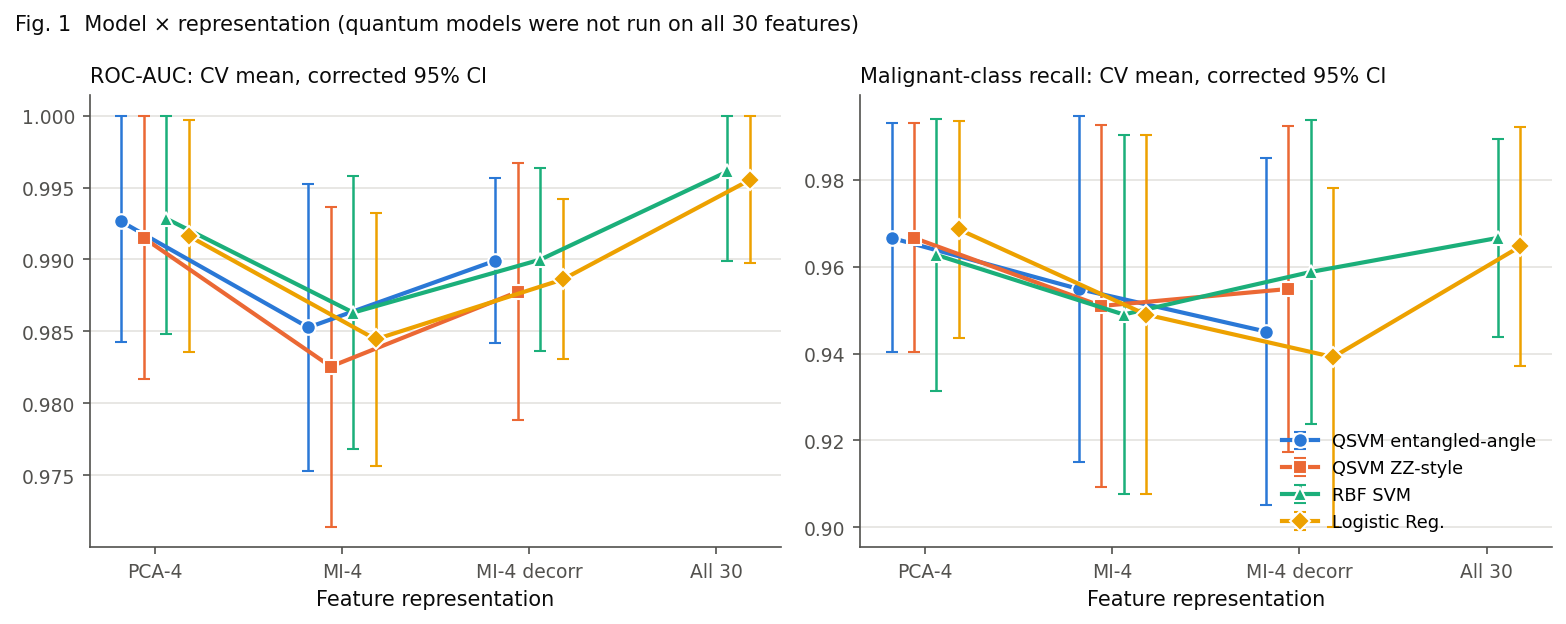

saved /content/sc4055_data/figures/p4_fig1_model_by_representation.png


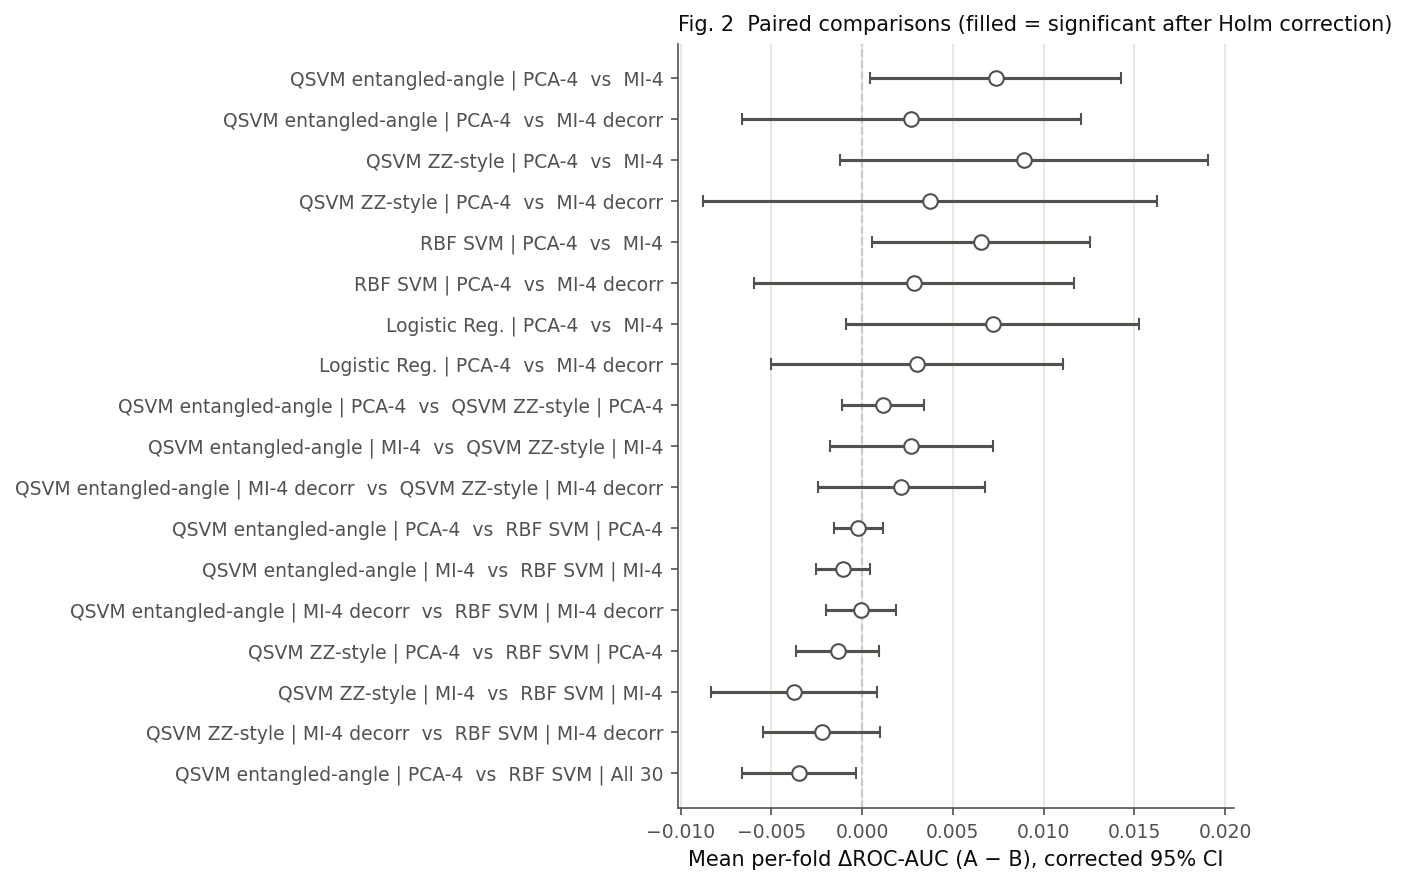

saved /content/sc4055_data/figures/p4_fig2_paired_comparisons.png


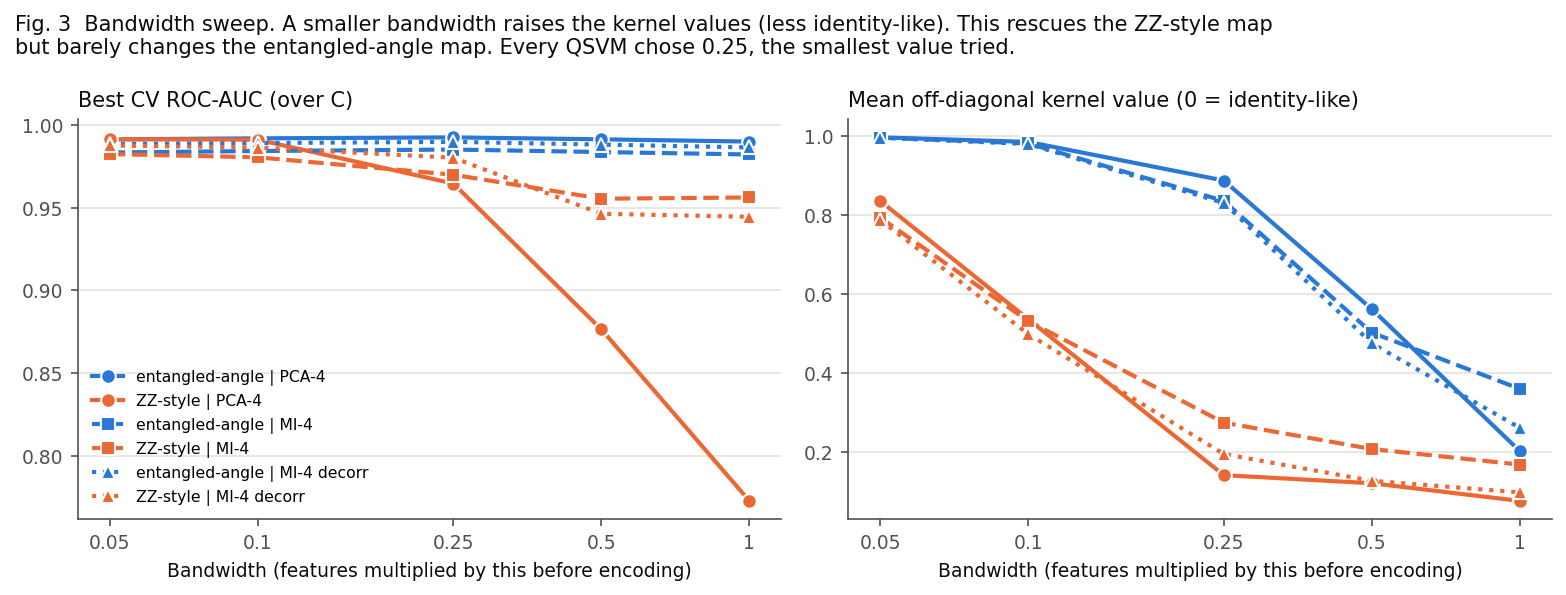

saved /content/sc4055_data/figures/p4_fig3_bandwidth.png


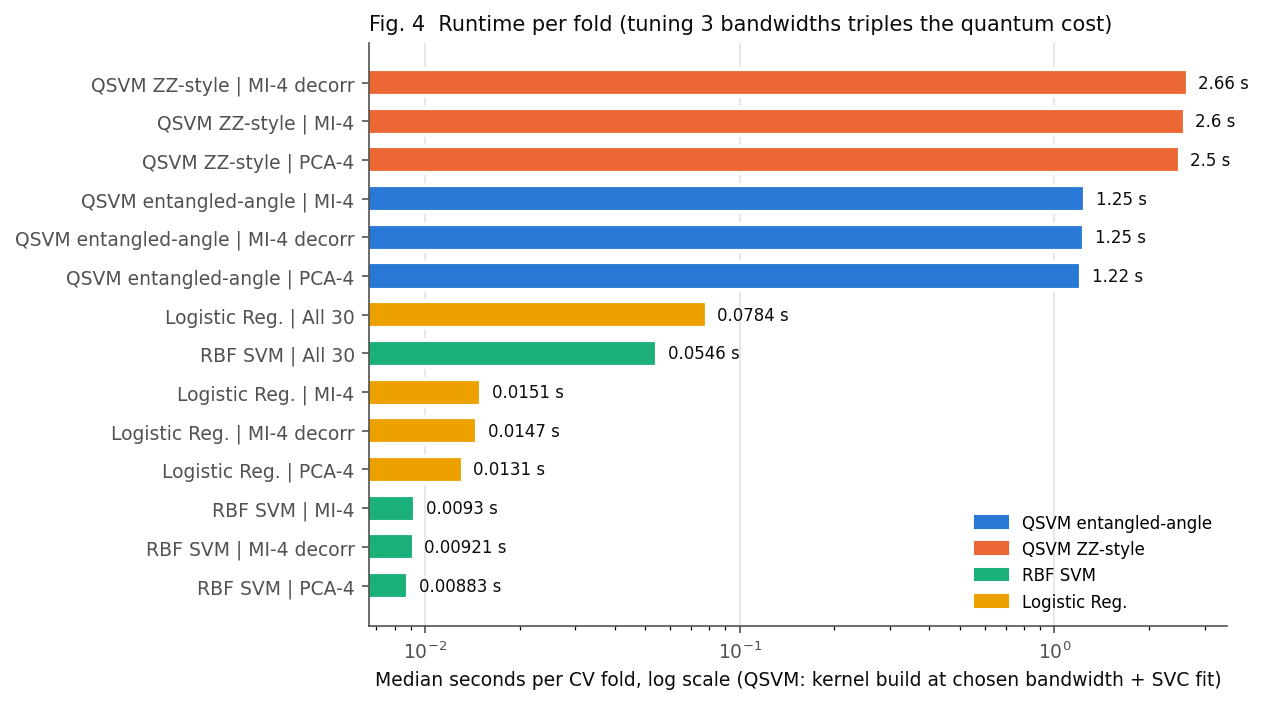

saved /content/sc4055_data/figures/p4_fig4_runtime.png


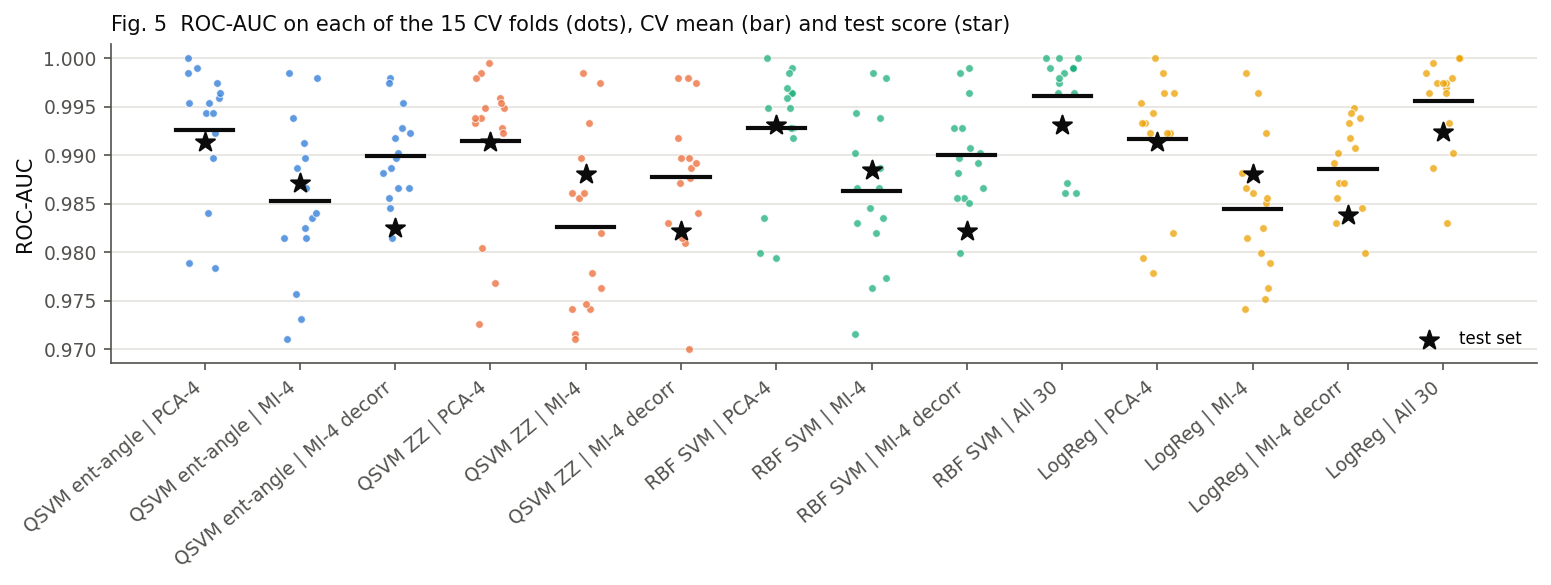

saved /content/sc4055_data/figures/p4_fig5_fold_variability.png

KEY NUMBERS
  best overall (CV AUC): RBF SVM | All 30  0.996
  best quantum (CV AUC): QSVM entangled-angle | PCA-4  0.993
  significant comparisons after Holm: 0 of 18
  quantum kernel build, all 16 kernels at the chosen bandwidth: 20-45 s per experiment; classical fit: 14 ms median per fold


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score

pd.options.display.float_format = "{:.3f}".format
P4_FIG_DIR = os.path.join(DATA_DIR, "figures")
os.makedirs(P4_FIG_DIR, exist_ok=True)

P4_MODEL_LABEL = {("qsvm", "angle_ent"): "QSVM entangled-angle", ("qsvm", "zz"): "QSVM ZZ-style",
                  ("rbf_svm", ""): "RBF SVM", ("logreg", ""): "Logistic Reg."}
P4_MODELS = list(P4_MODEL_LABEL.values())
P4_REP_LABEL = {"pca": "PCA-4", "mi": "MI-4", "mi_decorr": "MI-4 decorr", "full30": "All 30"}
P4_REPS = ["pca", "mi", "mi_decorr", "full30"]
P4_COLOR = {"QSVM entangled-angle": "#2a78d6", "QSVM ZZ-style": "#eb6834",
            "RBF SVM": "#1baf7a", "Logistic Reg.": "#eda100"}
P4_MARKER = {"QSVM entangled-angle": "o", "QSVM ZZ-style": "s", "RBF SVM": "^", "Logistic Reg.": "D"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"


def p4_style(ax, grid_axis="y"):
    ax.grid(axis=grid_axis, color=GRID, lw=0.8, zorder=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=9)


def p4_save(fig, name):
    path = os.path.join(P4_FIG_DIR, name)
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print("saved", path)



# One integrated table: every model x representation x fold (+ the test row)
p4_q = res_q.rename(columns={"Exp": "exp"}).copy()
P4_EXP_OF = {(r["rep"], r["feature_map"]): e for e, r in results.items()}

# Per-fold kernel-build time at the chosen bandwidth. res_q stores the total over all 16
# builds; the cache file of each build keeps its own original compute time.
p4_ktime = []
for _, row in p4_q.iterrows():
    e, fmap, sc = row["exp"], row["map"], row["scale"]
    if row["fold"] == "test":
        Za, _, Zb, _ = prep.get_final(row["rep"]); tag = f"{e}_final"
    else:
        Za, _, Zb, _ = prep.get_fold(row["rep"], int(row["fold"])); tag = f"{e}_f{int(row['fold']):02d}"
    p4_ktime.append(_build(tag, Za, Zb, fmap, sc)[2]["total_s"])
p4_q["kernel_time_s"] = p4_ktime

p4_c = res.copy()
p4_c["exp"], p4_c["scale"] = "", np.nan
P4_ALL = pd.concat([p4_q, p4_c], ignore_index=True)
P4_ALL["map"] = P4_ALL["map"].fillna("")
P4_ALL["family"] = np.where(P4_ALL["model"] == "qsvm", "QML", "CML")
P4_ALL["model_label"] = [P4_MODEL_LABEL[(m, f)] for m, f in zip(P4_ALL["model"], P4_ALL["map"])]
P4_ALL["rep_label"] = P4_ALL["rep"].map(P4_REP_LABEL)
P4_ALL["config"] = P4_ALL["model_label"] + " | " + P4_ALL["rep_label"]
# time for one fold = kernel build (QML only; RBF/LR compute their kernel inside fit) + fit/predict
P4_ALL["time_per_fold_s"] = P4_ALL["kernel_time_s"].fillna(0) + P4_ALL["fit_time_s"]
P4_ALL.to_csv(os.path.join(DATA_DIR, "p4_integrated_results.csv"), index=False)

P4_CV = P4_ALL[P4_ALL.fold != "test"].copy()
P4_CV["fold"] = P4_CV["fold"].astype(int)
P4_TEST = P4_ALL[P4_ALL.fold == "test"].set_index("config")


def cfg(model_label, rep):
    return f"{model_label} | {P4_REP_LABEL[rep]}"


def per_fold(config, metric="roc_auc"):
    return P4_CV[P4_CV.config == config].sort_values("fold")[metric].to_numpy()


# Sanity: every model saw the same 15 folds, and no chosen model predicts a single class
assert P4_CV.groupby("config")["fold"].apply(lambda f: sorted(f) == list(range(prep.N_FOLDS))).all()
assert (P4_CV.groupby("config")["recall"].min() > 0).all(), "a chosen model predicts only benign on some fold"

# -----------------Test-set predictions for bootstrap CIs and McNemar-----------------

P4_PRED = {}   # config -> (y_test, predicted label, score)

def p4_refit(model, Xf, yf, Xe, ye):
    model.fit(Xf, yf)
    sc = model.predict_proba(Xe)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(Xe)
    return ye, model.predict(Xe), sc


for c, row in P4_TEST.iterrows():
    if row["model"] == "qsvm":
        K_tr, K_te, y_tr, y_te = results[row["exp"]]["by_scale"][row["scale"]]["final"]
        P4_PRED[c] = p4_refit(qsvc(row["C"]), K_tr, y_tr, K_te, y_te)
    else:
        m = rbf(row["C"], row["gamma"]) if row["model"] == "rbf_svm" else logreg(row["C"])
        P4_PRED[c] = p4_refit(yj(m), *final30) if row["rep"] == "full30" else p4_refit(m, *prep.get_final(row["rep"]))
    yt, pr, sc = P4_PRED[c]       # the refit must reproduce the stored test scores
    assert np.isclose(roc_auc_score(yt, sc), row["roc_auc"]) and np.isclose(recall_score(yt, pr), row["recall"]), c


# -----------Uncertainty: corrected CV intervals and test-set bootstrap intervals------------

# The 15 folds are 3 repeats of 5-fold CV, so their training sets overlap and std/sqrt(15)
# would be too optimistic. Nadeau & Bengio (2003) correction: var * (1/J + n_val/n_fit).
P4_RHO = 91 / 364


def corrected_ci(x, level=0.95):
    x = np.asarray(x, float)
    se = np.sqrt((1 / len(x) + P4_RHO) * x.var(ddof=1))
    h = stats.t.ppf(0.5 + level / 2, len(x) - 1) * se
    return x.mean() - h, x.mean() + h


def corrected_ttest(d):
    d = np.asarray(d, float)
    se = np.sqrt((1 / len(d) + P4_RHO) * d.var(ddof=1))
    if se == 0:
        return 0.0, 1.0
    t = d.mean() / se
    return t, 2 * stats.t.sf(abs(t), len(d) - 1)


# Stratified bootstrap of the 114 test rows (each resample keeps 42 malignant / 72 benign)
p4_rng = np.random.default_rng(prep.SEED)
p4_yt = next(iter(P4_PRED.values()))[0]
p4_pos, p4_neg = np.where(p4_yt == 1)[0], np.where(p4_yt == 0)[0]
P4_BOOT = [np.concatenate([p4_rng.choice(p4_pos, len(p4_pos)), p4_rng.choice(p4_neg, len(p4_neg))])
           for _ in range(2000)]


def boot_ci(c, metric):
    yt, pr, sc = P4_PRED[c]
    f = {"roc_auc": lambda b: roc_auc_score(yt[b], sc[b]), "recall": lambda b: recall_score(yt[b], pr[b])}[metric]
    return np.percentile([f(b) for b in P4_BOOT], [2.5, 97.5])


p4_rows = []
for ml in P4_MODELS:
    for rep in P4_REPS:
        c = cfg(ml, rep)
        if c not in P4_TEST.index:
            continue
        g, t = P4_CV[P4_CV.config == c], P4_TEST.loc[c]
        params = f"C={t['C']:g}"
        params += f", bandwidth={t['scale']:g}" if t["model"] == "qsvm" else ""
        params += f", gamma={t['gamma']:g}" if t["model"] == "rbf_svm" else ""
        row = {"family": t["family"], "model": ml, "representation": P4_REP_LABEL[rep], "chosen": params}
        for m in ["roc_auc", "recall"]:
            lo, hi = corrected_ci(g[m]); blo, bhi = boot_ci(c, m)
            row[f"{m} CV [95% CI]"] = f"{g[m].mean():.3f} [{lo:.3f}, {min(hi, 1):.3f}]"
            row[f"{m} test [95% CI]"] = f"{t[m]:.3f} [{blo:.3f}, {bhi:.3f}]"
        for m in ["f1", "accuracy"]:
            row[f"{m} CV"] = f"{g[m].mean():.3f} ± {g[m].std():.3f}"
            row[f"{m} test"] = round(t[m], 3)
        row["s / fold"] = round(g["time_per_fold_s"].median(), 3)
        p4_rows.append(row)
P4_SUMMARY = pd.DataFrame(p4_rows)
P4_SUMMARY.to_csv(os.path.join(DATA_DIR, "p4_summary.csv"), index=False)
print("TABLE 1. Integrated results. Positive class = malignant (1). CV: mean over 15 folds with "
      "Nadeau-Bengio corrected 95% CI. Test: 114 held-out rows, stratified-bootstrap 95% CI.")
display(P4_SUMMARY)


# -----------------Planned comparisons (paired on the same folds), Holm-corrected-----------------

def mcnemar_exact(a, b):
    yt, pa, _ = P4_PRED[a]; _, pb, _ = P4_PRED[b]
    a_only, b_only = int(((pa == yt) & (pb != yt)).sum()), int(((pa != yt) & (pb == yt)).sum())
    n = a_only + b_only
    return a_only, b_only, (1.0 if n == 0 else stats.binomtest(min(a_only, b_only), n, 0.5).pvalue)


def holm(p):
    p = np.asarray(p, float); out = np.empty_like(p); run = 0.0
    for k, i in enumerate(np.argsort(p)):
        run = max(run, min(1.0, (len(p) - k) * p[i])); out[i] = run
    return out


P4_COMPARISONS = []
for ml in P4_MODELS:                                     # RQ1: representation, within each model
    for rep in ["mi", "mi_decorr"]:
        P4_COMPARISONS.append(("RQ1 representation", cfg(ml, "pca"), cfg(ml, rep)))
for rep in ["pca", "mi", "mi_decorr"]:                   # RQ2: quantum map, within each representation
    P4_COMPARISONS.append(("RQ2 quantum map", cfg("QSVM entangled-angle", rep), cfg("QSVM ZZ-style", rep)))
for qm in ["QSVM entangled-angle", "QSVM ZZ-style"]:     # QML vs CML on identical inputs
    for rep in ["pca", "mi", "mi_decorr"]:
        P4_COMPARISONS.append(("QML vs CML", cfg(qm, rep), cfg("RBF SVM", rep)))
p4_best_q = P4_CV[P4_CV.family == "QML"].groupby("config")["roc_auc"].mean().idxmax()
P4_COMPARISONS.append(("QML vs CML", p4_best_q, cfg("RBF SVM", "full30")))   # best QML vs 30-feature reference

p4_stat = []
for rq, a, b in P4_COMPARISONS:
    d = per_fold(a) - per_fold(b)
    t, p = corrected_ttest(d)
    lo, hi = corrected_ci(d)
    a_only, b_only, p_mc = mcnemar_exact(a, b)
    p4_stat.append({"question": rq, "A": a, "B": b, "mean ΔAUC (A−B)": d.mean(),
                    "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "folds A>B": f"{int((d > 0).sum())}/15",
                    "p": p, "test: only A right": a_only, "test: only B right": b_only, "McNemar p": p_mc})
P4_STATS = pd.DataFrame(p4_stat)
P4_STATS["p (Holm)"] = holm(P4_STATS["p"])
P4_STATS["McNemar p (Holm)"] = holm(P4_STATS["McNemar p"])
P4_STATS["significant"] = np.where(P4_STATS["p (Holm)"] < 0.05, "yes", "no")
P4_STATS.to_csv(os.path.join(DATA_DIR, "p4_significance_tests.csv"), index=False)
print("\nTABLE 2. Paired comparisons on the 15 CV folds (corrected resampled t-test) and on the "
      "test set (exact McNemar). p-values Holm-adjusted across all rows.")
display(P4_STATS)

# RQ3: Per-fold interaction contrast [QSVM(PCA) − QSVM(MI)] − [RBF(PCA) − RBF(MI)]
p4_int = []
for qm in ["QSVM entangled-angle", "QSVM ZZ-style"]:
    for rep in ["mi", "mi_decorr"]:
        d = ((per_fold(cfg(qm, "pca")) - per_fold(cfg(qm, rep)))
             - (per_fold(cfg("RBF SVM", "pca")) - per_fold(cfg("RBF SVM", rep))))
        t, p = corrected_ttest(d)
        p4_int.append({"quantum model": qm, "contrast": f"(PCA-4 − {P4_REP_LABEL[rep]}) for QSVM minus same for RBF SVM",
                       "mean ΔΔAUC": d.mean(), "t": t, "p": p})
P4_INTER = pd.DataFrame(p4_int)
P4_INTER["p (Holm)"] = holm(P4_INTER["p"])
P4_INTER.to_csv(os.path.join(DATA_DIR, "p4_interaction_tests.csv"), index=False)
print("\nTABLE 3. RQ3 interaction: does changing the representation move QML and CML differently?")
display(P4_INTER)

# -----------------Kernel concentration across bandwidths-----------------

# Kernel-target alignment (KTA) measures how well K lines up with the label structure y y^T.
p4_bw = []
for e, r in results.items():
    ml = P4_MODEL_LABEL[("qsvm", r["feature_map"])]
    for sc, rs in r["by_scale"].items():
        K, y_tr = rs["final"][0], rs["final"][2]
        off = K[~np.eye(len(K), dtype=bool)]
        Y = np.outer(2 * y_tr - 1, 2 * y_tr - 1)
        kta = (K * Y).sum() / np.sqrt((K * K).sum() * (Y * Y).sum())
        best_auc = max(np.mean([score_kernel(C, *fold)["roc_auc"] for fold in rs["folds"]]) for C in CS)
        p4_bw.append({"exp": e, "model": ml, "representation": P4_REP_LABEL[r["rep"]], "bandwidth": sc,
                      "off-diag mean": off.mean(), "share < 0.05": (off < 0.05).mean(),
                      "KTA": kta, "best CV AUC over C": best_auc})
P4_BW = pd.DataFrame(p4_bw)
P4_BW.to_csv(os.path.join(DATA_DIR, "p4_bandwidth_diagnostics.csv"), index=False)
print("\nTABLE 4. Kernel concentration and CV ROC-AUC at each bandwidth (final-train kernels)")
display(P4_BW)

# -----------------Figures-----------------

# Fig 1: representation x model (RQ1, RQ2, RQ3)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), dpi=150)
off = {m: (k - 1.5) * 0.12 for k, m in enumerate(P4_MODELS)}
for ax, metric, title in zip(axes, ["roc_auc", "recall"], ["ROC-AUC", "Malignant-class recall"]):
    for ml in P4_MODELS:
        xs, ms, lo, hi = [], [], [], []
        for i, rep in enumerate(P4_REPS):
            g = per_fold(cfg(ml, rep), metric)
            if len(g) == 0:
                continue
            a, b = corrected_ci(g)
            xs.append(i + off[ml]); ms.append(g.mean()); lo.append(g.mean() - a); hi.append(min(b, 1) - g.mean())
        ax.errorbar(xs, ms, yerr=[lo, hi], color=P4_COLOR[ml], marker=P4_MARKER[ml], ms=7, lw=2, capsize=3,
                    elinewidth=1.2, label=ml, zorder=3, markeredgecolor="white", markeredgewidth=1)
    ax.set_xticks(range(len(P4_REPS)), [P4_REP_LABEL[r] for r in P4_REPS])
    ax.set_title(f"{title}: CV mean, corrected 95% CI", color=INK, fontsize=10, loc="left")
    ax.set_xlabel("Feature representation", color=INK)
    p4_style(ax)
axes[1].legend(frameon=False, fontsize=8.5, loc="lower right")
fig.suptitle("Fig. 1  Model × representation (quantum models were not run on all 30 features)",
             color=INK, fontsize=10, x=0.01, ha="left")
fig.tight_layout()
p4_save(fig, "p4_fig1_model_by_representation.png")

# Fig 2: forest plot of the planned comparisons
fig, ax = plt.subplots(figsize=(8.5, 6), dpi=150)
for k, (_, row) in enumerate(P4_STATS.iterrows()):
    d = per_fold(row["A"]) - per_fold(row["B"])
    a, b = corrected_ci(d)
    sig = row["significant"] == "yes"
    yk = len(P4_STATS) - 1 - k
    ax.errorbar(d.mean(), yk, xerr=[[d.mean() - a], [b - d.mean()]], fmt="o", ms=7, capsize=3, lw=1.5,
                color=INK if sig else MUTED, mfc=INK if sig else "white", zorder=3)
same = [r["A"].split(" | ")[0] == r["B"].split(" | ")[0] for _, r in P4_STATS.iterrows()]
labels = [f"{r['A']}  vs  {r['B'].split(' | ')[1] if s_ else r['B']}" for (_, r), s_ in zip(P4_STATS.iterrows(), same)]
ax.set_yticks(range(len(labels))[::-1], labels, fontsize=8)
ax.axvline(0, color=MUTED, lw=1, ls="--", zorder=1)
ax.set_xlabel("Mean per-fold ΔROC-AUC (A − B), corrected 95% CI", color=INK)
ax.set_title("Fig. 2  Paired comparisons (filled = significant after Holm correction)", color=INK, fontsize=10, loc="left")
p4_style(ax, "x")
fig.tight_layout()
p4_save(fig, "p4_fig2_paired_comparisons.png")

# Fig 3: bandwidth sweep: CV AUC and kernel concentration
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), dpi=150)
rep_marker = {"PCA-4": "o", "MI-4": "s", "MI-4 decorr": "^"}
rep_ls = {"PCA-4": "-", "MI-4": "--", "MI-4 decorr": ":"}
for (ml, rl), g in P4_BW.groupby(["model", "representation"], sort=False):
    g = g.sort_values("bandwidth")
    for ax, col in zip(axes, ["best CV AUC over C", "off-diag mean"]):
        ax.plot(g["bandwidth"], g[col], color=P4_COLOR[ml], marker=rep_marker[rl], ls=rep_ls[rl], lw=2, ms=7,
                markeredgecolor="white", label=f"{ml.replace('QSVM ', '')} | {rl}", zorder=3)
for ax, t in zip(axes, ["Best CV ROC-AUC (over C)", "Mean off-diagonal kernel value (0 = identity-like)"]):
    ax.set_xscale("log", base=2)
    ax.set_xticks(BANDWIDTHS, [f"{b:g}" for b in BANDWIDTHS])
    ax.set_xlabel("Bandwidth (features multiplied by this before encoding)", color=INK, fontsize=9)
    ax.set_title(t, color=INK, fontsize=10, loc="left")
    p4_style(ax)
axes[0].legend(frameon=False, fontsize=7.5, loc="lower left")
fig.suptitle("Fig. 3  Bandwidth sweep. A smaller bandwidth raises the kernel values (less identity-like). This rescues the ZZ-style map\n"
             "but barely changes the entangled-angle map. Every QSVM chose 0.25, the smallest value tried.",
             color=INK, fontsize=10, x=0.01, ha="left")
fig.tight_layout()
p4_save(fig, "p4_fig3_bandwidth.png")

# Fig 4: runtime per CV fold (RQ4)
p4_rt = (P4_CV.groupby(["config", "model_label"])["time_per_fold_s"].median().reset_index()
         .sort_values("time_per_fold_s"))
fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=150)
ax.barh(p4_rt["config"], p4_rt["time_per_fold_s"], color=[P4_COLOR[m] for m in p4_rt["model_label"]],
        height=0.7, edgecolor="white", linewidth=2, zorder=2)
for i, v in enumerate(p4_rt["time_per_fold_s"]):
    ax.text(v * 1.08, i, f"{v:.3g} s", va="center", fontsize=8, color=INK)
ax.set_xscale("log")
ax.set_xlabel("Median seconds per CV fold, log scale (QSVM: kernel build at chosen bandwidth + SVC fit)",
              color=INK, fontsize=9)
ax.set_title("Fig. 4  Runtime per fold (tuning 3 bandwidths triples the quantum cost)", color=INK, fontsize=10, loc="left")
ax.tick_params(axis="y", labelsize=8)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=P4_COLOR[m]) for m in P4_MODELS], P4_MODELS,
          frameon=False, fontsize=8, loc="lower right")
p4_style(ax, "x")
fig.tight_layout()
p4_save(fig, "p4_fig4_runtime.png")

# Fig 5: per-fold spread, the variability that the significance tests have to see through
fig, ax = plt.subplots(figsize=(10.5, 4), dpi=150)
p4_order = [cfg(ml, rep) for ml in P4_MODELS for rep in P4_REPS if cfg(ml, rep) in P4_TEST.index]
p4_jit = np.random.default_rng(0)
for i, c in enumerate(p4_order):
    v = per_fold(c); ml = c.split(" | ")[0]
    ax.scatter(i + p4_jit.uniform(-0.18, 0.18, len(v)), v, s=14, color=P4_COLOR[ml], alpha=0.75,
               edgecolor="white", linewidth=0.5, zorder=3)
    ax.plot([i - 0.3, i + 0.3], [v.mean()] * 2, color=INK, lw=2, zorder=4)
    ax.scatter(i, P4_TEST.loc[c, "roc_auc"], marker="*", s=90, color=INK, zorder=5,
               label="test set" if i == 0 else None)
P4_SHORT = {"QSVM entangled-angle": "QSVM ent-angle", "QSVM ZZ-style": "QSVM ZZ", "RBF SVM": "RBF SVM", "Logistic Reg.": "LogReg"}
ax.set_xticks(range(len(p4_order)), [f"{P4_SHORT[c.split(' | ')[0]]} | {c.split(' | ')[1]}" for c in p4_order],
              fontsize=7.5, rotation=40, ha="right")
ax.set_ylabel("ROC-AUC", color=INK)
ax.set_title("Fig. 5  ROC-AUC on each of the 15 CV folds (dots), CV mean (bar) and test score (star)",
             color=INK, fontsize=10, loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
p4_style(ax)
fig.tight_layout()
p4_save(fig, "p4_fig5_fold_variability.png")


p4_m = P4_CV.groupby("config")["roc_auc"].mean()
print("\nKEY NUMBERS")
print(f"  best overall (CV AUC): {p4_m.idxmax()}  {p4_m.max():.3f}")
print(f"  best quantum (CV AUC): {p4_best_q}  {p4_m[p4_best_q]:.3f}")
print(f"  significant comparisons after Holm: {int((P4_STATS['significant'] == 'yes').sum())} of {len(P4_STATS)}")
for _, r in P4_STATS[P4_STATS["significant"] == "yes"].iterrows():
    print(f"    {r['A']}  vs  {r['B']}: ΔAUC {r['mean ΔAUC (A−B)']:+.3f}, Holm p {r['p (Holm)']:.3g}")
print(f"  quantum kernel build, all 16 kernels at the chosen bandwidth: "
      f"{p4_q.groupby('exp')['kernel_time_s'].sum().min():.0f}-{p4_q.groupby('exp')['kernel_time_s'].sum().max():.0f} s per experiment; "
      f"classical fit: {P4_CV[P4_CV.family == 'CML']['fit_time_s'].median() * 1000:.0f} ms median per fold")
